# [기초-실습] 통계 101×데이터 분석: (7장) 상관과 회귀

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비

### 1단계 · 한글 폰트 설치

- 그래프에 한글이 깨지지 않도록 나눔 폰트를 설치합니다.

- 실행 후 **[런타임] - [세션 다시 시작]**을 한 번 눌러야 폰트가 적용됩니다.

In [2]:
# 구글 코랩 환경에서 한글 폰트 설치 및 설정하기
# 필요시 아래 코드 실행 후, [런타임] - [세션 다시 시작] 후 셀을 다시 실행하세요.
!pip install statsmodels
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists...
Building dependency tree...
Reading state information...
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
Font directories:
	/root/.local/share/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/root/.fonts
	/usr/share/fonts/truetype
	/usr/share/fonts/truetype/humor-sans
	/usr/share/fonts/truetype/liberation
	/usr/share/fonts/truetype/nanum
/root/.local/share/fonts: skipping, no such directory
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 12 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/root/.fonts: skipping, no such directory
/usr/share/fonts/

### 2단계 · 라이브러리 불러오기

- 이번 실습에서 쓰는 도구입니다. **한 번만 실행**해 두면 끝까지 사용합니다.

- `smf`는 회귀식을 `'y ~ x'` 형태로 쓰는 모듈, `het_breuschpagan`은 등분산 검정 함수입니다.

In [3]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'NanumGothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

## 문제 1 · 펭귄의 부리는 길수록 두꺼울까?

`난이도 하` · `예상 15분`

**📖 상황**

- 남극 팔머 기지에서 측정한 펭귄 344마리의 신체 데이터(`penguins`)를 사용합니다.

- 부리 길이(`bill_length_mm`)와 부리 두께(`bill_depth_mm`)가 함께 어떻게 움직이는지 봅니다.

- 그런데 이 데이터에는 **세 종(Adelie·Chinstrap·Gentoo)이 섞여 있습니다.**
  전체를 뭉쳐서 볼 때와 집단을 나눠서 볼 때 **결론이 정반대로 뒤집히는 일**이 실제로 일어납니다.

**🎯 이 문제로 배우는 것**

- 상관계수를 계산하기 **전에** 산점도를 먼저 그려야 하는 이유를, 숫자로 직접 확인합니다.

In [4]:
# 문제 1 · 데이터 준비 — 실행만 하세요
penguins = sns.load_dataset('penguins')

print("데이터 크기:", penguins.shape)
print("\n종별 개체 수:")
print(penguins['species'].value_counts())
print("\n결측치 개수:")
print(penguins.isna().sum())

penguins.head()

데이터 크기: (344, 7)

종별 개체 수:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

결측치 개수:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g     sex
0  Adelie  Torgersen            39.1           18.7              181.0       3750.0    Male
1  Adelie  Torgersen            39.5           17.4              186.0       3800.0  Female
2  Adelie  Torgersen            40.3           18.0              195.0       3250.0  Female
3  Adelie  Torgersen             NaN            NaN                NaN          NaN     NaN
4  Adelie  Torgersen            36.7           19.3              193.0       3450.0  Female


### Q1 · 산점도로 두 변수의 관계를 그려 봅시다

- 가로축 `bill_length_mm`, 세로축 `bill_depth_mm`로 산점도를 그리세요.

- 그래프 제목과 축 라벨을 한글로 알아보기 쉽게 설정하세요.

- `💡 힌트` `sns.scatterplot(data=..., x=..., y=...)` / `plt.title()`, `plt.xlabel()`, `plt.ylabel()`

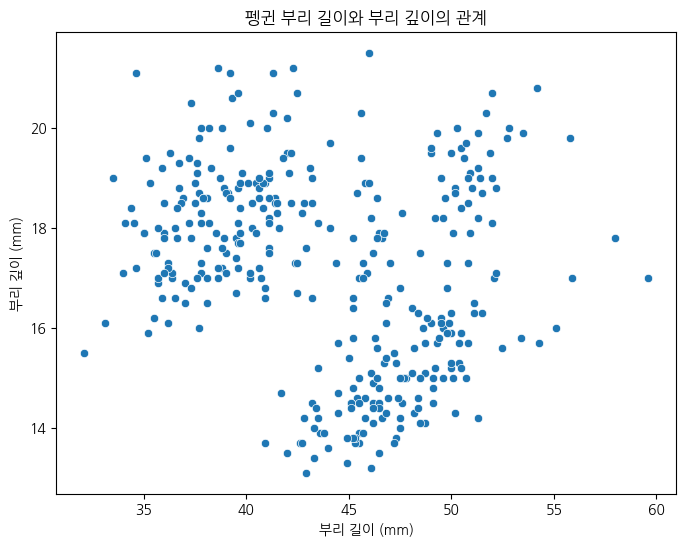

In [5]:
import os, platform, urllib.request
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# ── 한글 폰트 설정 ──────────────────────────────
if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
else:  # Colab / Linux
    path = '/tmp/NanumGothic.ttf'
    if not os.path.exists(path):
        urllib.request.urlretrieve(
            'https://github.com/google/fonts/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', path)
    fm.fontManager.addfont(path)
    plt.rcParams['font.family'] = fm.FontProperties(fname=path).get_name()
plt.rcParams['axes.unicode_minus'] = False

# ── Q1 · 산점도 ────────────────────────────────
penguins = sns.load_dataset('penguins')

plt.figure(figsize=(8, 6))
sns.scatterplot(data=penguins, x='bill_length_mm', y='bill_depth_mm')

plt.title('펭귄 부리 길이와 부리 깊이의 관계')
plt.xlabel('부리 길이 (mm)')
plt.ylabel('부리 깊이 (mm)')
plt.show()

### Q2 · 종별로 색을 나눠 같은 그림을 다시 그려 봅시다

- Q1과 똑같은 산점도에 펭귄의 종(`species`)별로 점의 색을 다르게 칠하세요.

- Q1의 그림과 나란히 놓고 무엇이 달라 보이는지 관찰하세요.

- `💡 힌트` `sns.scatterplot()`에 `hue` 인수를 추가해 보세요.

[관찰 결과]
1. Q1(색 구분 없음): 부리가 길수록 얕아지는 듯한 약한 음의 관계로 보인다 (전체 상관계수 -0.24).
    하지만 점들이 세 무리로 뭉쳐 있어 하나의 직선 관계로 보기 어색하다.
2. Q2(종별 색 구분): 세 무리는 각각 다른 종이다.
    Adelie = 부리가 짧고 깊음(왼쪽 위),  Chinstrap = 길고 깊음(오른쪽 위),  Gentoo = 길고 얕음(오른쪽 아래)
3. 종 안에서는 세 종 모두 부리가 길수록 깊어지는 '양의 관계'다
    (Adelie 0.39, Chinstrap 0.65, Gentoo 0.64) → Q1의 음의 관계는 종이 섞여서 생긴 착시였다.
4. 전체로 보면 관계가 뒤집혀 보이는 이 현상을 '심슨의 역설'이라고 한다.
    → 종 같은 제3의 변수를 고려하지 않으면 두 변수의 관계를 잘못 해석할 수 있다.


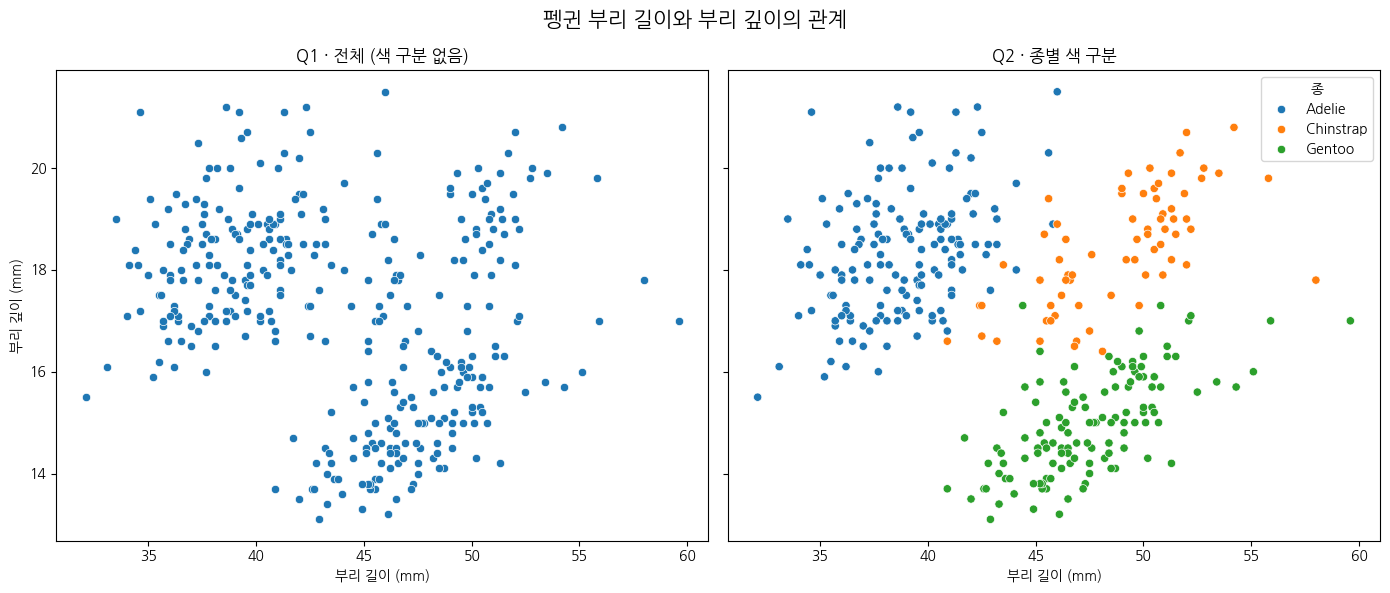

In [6]:
import os, platform, urllib.request
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# ── 한글 폰트 설정 ──────────────────────────────────────────
if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
else:  # Colab / Linux
    path = '/tmp/NanumGothic.ttf'
    if not os.path.exists(path):
        urllib.request.urlretrieve(
            'https://github.com/google/fonts/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', path)
    fm.fontManager.addfont(path)
    plt.rcParams['font.family'] = fm.FontProperties(fname=path).get_name()
plt.rcParams['axes.unicode_minus'] = False

# ── 데이터와 상관계수 ──────────────────────────────────────
penguins = sns.load_dataset('penguins')
df = penguins.dropna(subset=['bill_length_mm', 'bill_depth_mm'])
r_all = df['bill_length_mm'].corr(df['bill_depth_mm'])
r_sp = {s: g['bill_length_mm'].corr(g['bill_depth_mm']) for s, g in df.groupby('species')}

# ── 관찰 결과 문장 ─────────────────────────────────────────
observation = f"""[관찰 결과]
1. Q1(색 구분 없음): 부리가 길수록 얕아지는 듯한 약한 음의 관계로 보인다 (전체 상관계수 {r_all:.2f}).
    하지만 점들이 세 무리로 뭉쳐 있어 하나의 직선 관계로 보기 어색하다.
2. Q2(종별 색 구분): 세 무리는 각각 다른 종이다.
    Adelie = 부리가 짧고 깊음(왼쪽 위),  Chinstrap = 길고 깊음(오른쪽 위),  Gentoo = 길고 얕음(오른쪽 아래)
3. 종 안에서는 세 종 모두 부리가 길수록 깊어지는 '양의 관계'다
    (Adelie {r_sp['Adelie']:.2f}, Chinstrap {r_sp['Chinstrap']:.2f}, Gentoo {r_sp['Gentoo']:.2f}) → Q1의 음의 관계는 종이 섞여서 생긴 착시였다.
4. 전체로 보면 관계가 뒤집혀 보이는 이 현상을 '심슨의 역설'이라고 한다.
    → 종 같은 제3의 변수를 고려하지 않으면 두 변수의 관계를 잘못 해석할 수 있다."""

# ── Q1 · Q2 그래프 ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

sns.scatterplot(data=penguins, x='bill_length_mm', y='bill_depth_mm', ax=axes[0])
axes[0].set_title('Q1 · 전체 (색 구분 없음)')
axes[0].set_xlabel('부리 길이 (mm)')
axes[0].set_ylabel('부리 깊이 (mm)')

sns.scatterplot(data=penguins, x='bill_length_mm', y='bill_depth_mm',
                hue='species', ax=axes[1])
axes[1].set_title('Q2 · 종별 색 구분')
axes[1].set_xlabel('부리 길이 (mm)')
axes[1].set_ylabel('부리 깊이 (mm)')
axes[1].legend(title='종')

fig.suptitle('펭귄 부리 길이와 부리 깊이의 관계', fontsize=15)
plt.tight_layout()
plt.show()

# ── 관찰 결과 출력 ─────────────────────────────────────────
print(observation)

### Q3 · 상관계수를 '전체'와 '종별'로 각각 구해 비교해 봅시다

- 두 변수의 상관계수를 **전체 데이터**에 대해 계산하세요.

- 같은 상관계수를 **종별로 나누어** 계산하세요.

- 두 결과의 **부호**를 비교하세요.

- `💡 힌트` 전체는 `df[['A','B']].dropna().corr()`,
  종별은 `df.groupby('species')[['A','B']].corr()`를 활용해 보세요.

① 전체 상관계수: -0.24
② 종별 상관계수
   Adelie: 0.39
   Chinstrap: 0.65
   Gentoo: 0.64
③ 부호 비교
   전체: -0.24 음(-)
   Adelie: 0.39 양(+)
   Chinstrap: 0.65 양(+)
   Gentoo: 0.64 양(+)
-> 전체는 음(-), 종별은 모두 양(+)으로 부호가 반대 (심슨의 역설)


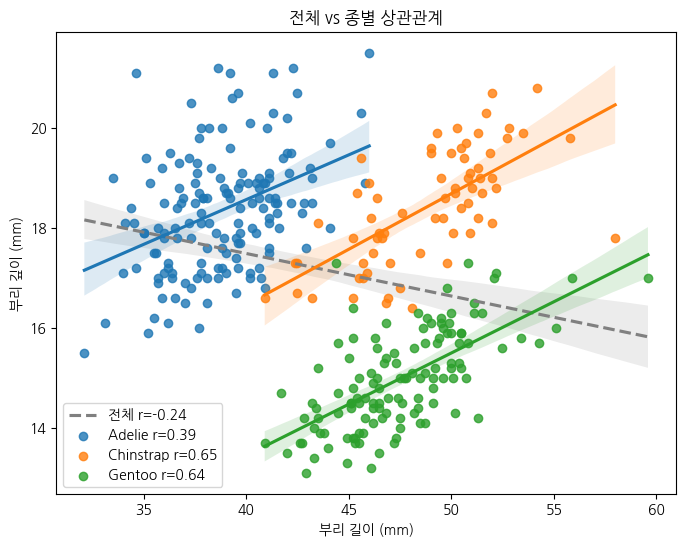

In [1]:
import os, platform, urllib.request
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

df = sns.load_dataset('penguins')
A, B = 'bill_length_mm', 'bill_depth_mm'
sg = lambda r: '양(+)' if r > 0 else '음(-)'

# ① 전체
r_all = df[[A, B]].dropna().corr().loc[A, B]
print(f"① 전체 상관계수: {r_all:.2f}")

# ② 종별
r_sp = df.groupby('species')[[A, B]].corr().xs(A, level=1)[B]
print("② 종별 상관계수")
for k, r in r_sp.items(): print(f"   {k}: {r:.2f}")

# ③ 부호 비교
print("③ 부호 비교")
print(f"   전체: {r_all:.2f} {sg(r_all)}")
for k, r in r_sp.items(): print(f"   {k}: {r:.2f} {sg(r)}")
print("-> 전체는 음(-), 종별은 모두 양(+)으로 부호가 반대 (심슨의 역설)")

# 그래프
plt.figure(figsize=(8, 6))
sns.regplot(data=df, x=A, y=B, scatter=False, color='gray',
            line_kws={'ls': '--'}, label=f'전체 r={r_all:.2f}')
for k in r_sp.index:
    sns.regplot(data=df[df.species == k], x=A, y=B,
                label=f'{k} r={r_sp[k]:.2f}')
plt.title('전체 vs 종별 상관관계')
plt.xlabel('부리 길이 (mm)'); plt.ylabel('부리 깊이 (mm)')
plt.legend(); plt.show()

### 💬 정리 · 결과를 말로 설명해 보기

- Q1의 산점도에서 두 변수는 어떤 방향의 관계로 보였나요? Q3의 전체 상관계수와 부호가 일치하나요?

- Q3의 종별 상관계수는 전체와 부호가 같나요, 다른가요?

- **같은 데이터인데 전체와 집단별 결론이 정반대로 나온 이유**를 설명해 보세요. 무엇이 이 착시를 만들고 있나요?

- 만약 이 데이터에 '종' 정보가 없었다면 우리는 어떤 잘못된 결론을 내렸을까요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 부호가 뒤집히는 열쇠는 **종마다 부리의 '기본 크기'가 다르다**는 데 있습니다. 종별 평균이 어디에 놓여 있는지를 Q2의 그림에서 확인해 보세요.

- "전체를 보면 음, 나누면 양"은 두 변수 사이에 **숨은 집단 변수**가 끼어 있을 때 나타납니다. 이 현상에는 이름이 붙어 있고, 다음 시간 인과추론에서 다시 만납니다.

- 결론의 형태를 이렇게 나눠 써 보면 정확해집니다 — "종을 무시하면 ○○, 종을 고려하면 ○○".

</details>

1. Q1은 부리가 길수록 얕아지는 음(-)의 관계로 보였다.
   Q3 전체 상관계수 -0.24도 음(-)으로 일치한다.

2. 종별 상관계수
   Adelie: 0.39 양(+)
   Chinstrap: 0.65 양(+)
   Gentoo: 0.64 양(+)
   -> 모두 양(+)으로 전체(음)와 부호가 다르다.

3. 이유: 종마다 부리의 평균 위치가 다르다.
          평균길이 평균깊이
species                    
Adelie        38.8     18.3
Chinstrap     48.8     18.4
Gentoo        47.5     15.0
   Gentoo는 길고 얕고, Adelie는 짧고 깊다.
   종 간 차이가 섞여 전체 경향이 아래로 기울었다.
   '종'이라는 제3의 변수가 착시를 만든다(심슨의 역설).

4. 종 정보가 없었다면 '부리가 길수록 얕다'고 잘못 결론냈을 것.
   실제로는 같은 종 안에서 부리가 길수록 더 깊다.


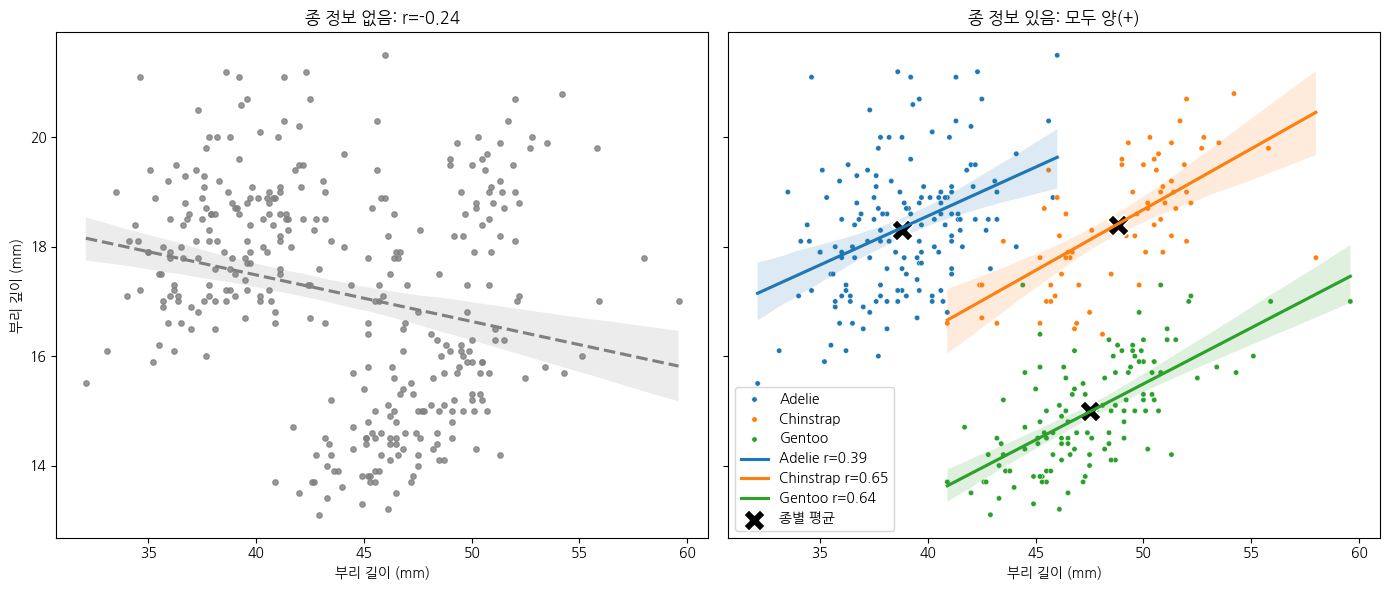

In [7]:
import os, platform, urllib.request
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

df = sns.load_dataset('penguins')
A, B = 'bill_length_mm', 'bill_depth_mm'
r_all = df[[A, B]].dropna().corr().loc[A, B]
r_sp = df.groupby('species')[[A, B]].corr().xs(A, level=1)[B]
m = df.groupby('species')[[A, B]].mean().round(1)

print("1. Q1은 부리가 길수록 얕아지는 음(-)의 관계로 보였다.")
print(f"   Q3 전체 상관계수 {r_all:.2f}도 음(-)으로 일치한다.\n")
print("2. 종별 상관계수")
for k, r in r_sp.items(): print(f"   {k}: {r:.2f} 양(+)")
print("   -> 모두 양(+)으로 전체(음)와 부호가 다르다.\n")
print("3. 이유: 종마다 부리의 평균 위치가 다르다.")
print(m.to_string(header=['평균길이', '평균깊이']))
print("   Gentoo는 길고 얕고, Adelie는 짧고 깊다.")
print("   종 간 차이가 섞여 전체 경향이 아래로 기울었다.")
print("   '종'이라는 제3의 변수가 착시를 만든다(심슨의 역설).\n")
print("4. 종 정보가 없었다면 '부리가 길수록 얕다'고 잘못 결론냈을 것.")
print("   실제로는 같은 종 안에서 부리가 길수록 더 깊다.")

fig, ax = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
sns.regplot(data=df, x=A, y=B, color='gray', ax=ax[0],
            scatter_kws={'s': 15}, line_kws={'ls': '--'})
ax[0].set_title(f'종 정보 없음: r={r_all:.2f}')
sns.scatterplot(data=df, x=A, y=B, hue='species', s=15, ax=ax[1])
for k in r_sp.index:
    sns.regplot(data=df[df.species == k], x=A, y=B,
                scatter=False, ax=ax[1], label=f'{k} r={r_sp[k]:.2f}')
sns.scatterplot(data=m.reset_index(), x=A, y=B, ax=ax[1],
                s=250, marker='X', color='black', label='종별 평균')
ax[1].set_title('종 정보 있음: 모두 양(+)')
for a in ax: a.set_xlabel('부리 길이 (mm)'); a.set_ylabel('부리 깊이 (mm)')
ax[1].legend(); plt.tight_layout(); plt.show()

## 문제 2 · 날개가 길면 몸무게도 무거울까? — 관계를 숫자로

`난이도 하` · `예상 20분`

**📖 상황**

- 문제 1에서 "숫자 전에 그림"을 배웠습니다. 이제 관계를 **숫자 하나**로 요약해 봅니다.

- 이번에는 **날개 길이(`flipper_length_mm`)와 몸무게(`body_mass_g`)**를 봅니다.
  이 두 변수는 **문제 5까지 계속 사용**하며, 상관 → 회귀 → 검정 → 진단으로 이어집니다.

- **피어슨 상관계수(r)**는 관계의 방향(부호)과 강도(절대값)를 −1~+1로 나타냅니다.
  다만 피어슨은 **두 변수가 정규분포라는 전제**에 기대는 모수적 방법입니다.

**🎯 이 문제로 배우는 것**

- 정규성 점검 → 피어슨(r과 p-값) → 스피어만 비교의 순서로, **강의에서 배운 절차 그대로** 상관을 구합니다.

결측치 제거 전: 344 행
결측치 제거 후: 342 행


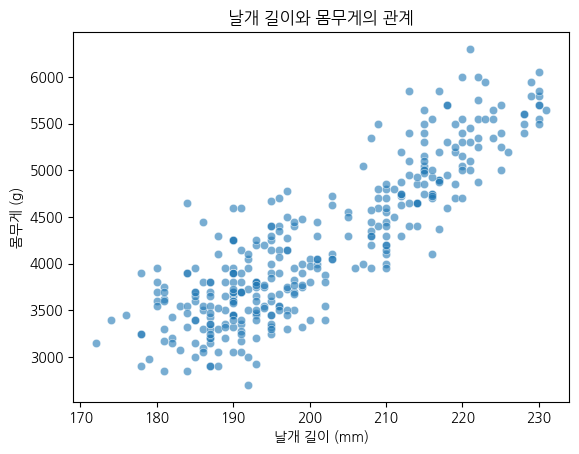

In [8]:
# 문제 2 · 데이터 준비 — 실행만 하세요
df_corr = penguins[['flipper_length_mm', 'body_mass_g']].dropna()

print("결측치 제거 전:", len(penguins), "행")
print("결측치 제거 후:", len(df_corr), "행")

# 두 변수의 관계를 그림으로 먼저 확인 (문제 1의 교훈!)
sns.scatterplot(data=df_corr, x='flipper_length_mm', y='body_mass_g', alpha=0.6)
plt.title("날개 길이와 몸무게의 관계")
plt.xlabel("날개 길이 (mm)")
plt.ylabel("몸무게 (g)")
plt.show()

### Q1 · 피어슨의 전제인 정규성을 점검해 봅시다

- `flipper_length_mm`과 `body_mass_g` **각각**에 대해 정규성 검정(Shapiro-Wilk)을 수행하세요.

- 유의수준 0.05를 기준으로 '정규성을 기각하는지'까지 함께 출력하세요.

- `💡 힌트` `stats.shapiro(데이터)`는 통계량과 p-값을 함께 돌려줍니다.

Q2 · 피어슨 상관계수 검정
H0: 모집단의 상관계수는 0이다 (상관 없음)
표본 크기 n = 342
r = 0.8712
p_value = 4.37e-107
-> p < 0.05이므로 H0 기각: 상관계수는 통계적으로 유의하다.
-> 날개가 길수록 몸무게가 무거운 매우 강한 양(+)의 상관 (r=0.87)


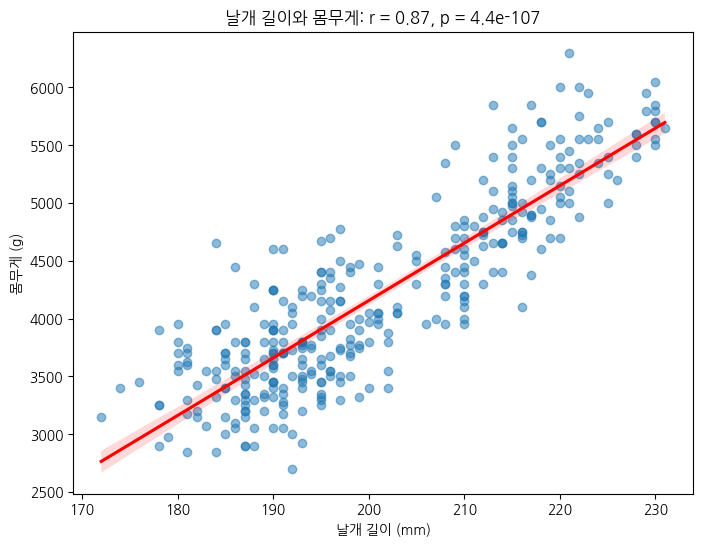

In [9]:
import os, platform, urllib.request
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from scipy import stats

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

penguins = sns.load_dataset('penguins')
df_corr = penguins[['flipper_length_mm', 'body_mass_g']].dropna()
x, y = df_corr['flipper_length_mm'], df_corr['body_mass_g']

# 피어슨 상관계수와 p-값 (H0: 모집단 상관계수 = 0)
r, p_value = stats.pearsonr(x, y)

print("Q2 · 피어슨 상관계수 검정")
print("H0: 모집단의 상관계수는 0이다 (상관 없음)")
print(f"표본 크기 n = {len(x)}")
print(f"r = {r:.4f}")
print(f"p_value = {p_value:.2e}")
if p_value < 0.05:
    print("-> p < 0.05이므로 H0 기각: 상관계수는 통계적으로 유의하다.")
else:
    print("-> p >= 0.05이므로 H0 기각 못 함: 상관이 있다고 보기 어렵다.")
print(f"-> 날개가 길수록 몸무게가 무거운 매우 강한 양(+)의 상관 (r={r:.2f})")

plt.figure(figsize=(8, 6))
sns.regplot(x=x, y=y, scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
plt.title(f"날개 길이와 몸무게: r = {r:.2f}, p = {p_value:.1e}")
plt.xlabel("날개 길이 (mm)"); plt.ylabel("몸무게 (g)")
plt.show()

### Q2 · 피어슨 상관계수와 p-값을 함께 구해 봅시다

- 상관계수만이 아니라 **p-값도 함께** 구하세요. 상관계수도 가설검정의 대상입니다.

- 결과는 반드시 `r`, `p_value`라는 이름으로 저장하세요. **문제 3·4에서 이어서 사용합니다.**

- `💡 힌트` `r, p_value = stats.pearsonr(x, y)` — 귀무가설은 "모집단의 상관계수가 0이다"입니다.

Q2 · 피어슨 상관계수 검정
H0: 모집단의 상관계수는 0이다 (상관 없음)
표본 크기 n = 342
r = 0.8712
p_value = 4.37e-107
-> p < 0.05이므로 H0 기각: 상관계수는 통계적으로 유의하다.
-> 날개가 길수록 몸무게가 무거운 매우 강한 양(+)의 상관 (r=0.87)


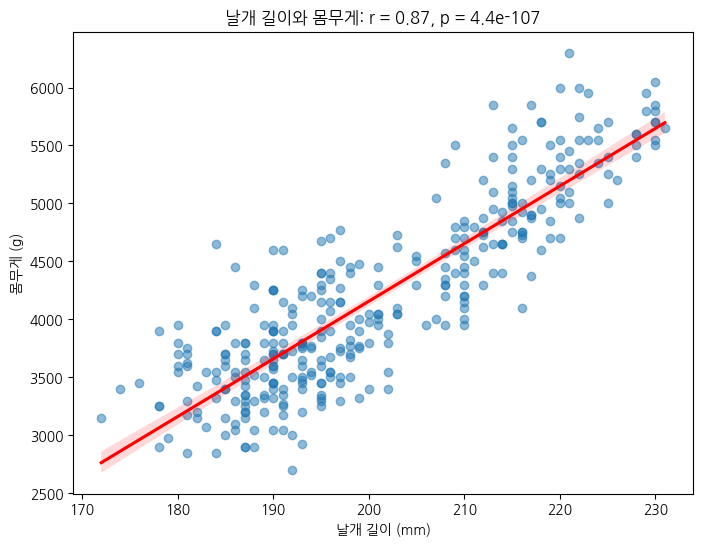

In [10]:
import os, platform, urllib.request
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from scipy import stats

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

penguins = sns.load_dataset('penguins')
df_corr = penguins[['flipper_length_mm', 'body_mass_g']].dropna()
x, y = df_corr['flipper_length_mm'], df_corr['body_mass_g']

# 피어슨 상관계수와 p-값 (H0: 모집단 상관계수 = 0)
r, p_value = stats.pearsonr(x, y)

print("Q2 · 피어슨 상관계수 검정")
print("H0: 모집단의 상관계수는 0이다 (상관 없음)")
print(f"표본 크기 n = {len(x)}")
print(f"r = {r:.4f}")
print(f"p_value = {p_value:.2e}")
if p_value < 0.05:
    print("-> p < 0.05이므로 H0 기각: 상관계수는 통계적으로 유의하다.")
else:
    print("-> p >= 0.05이므로 H0 기각 못 함: 상관이 있다고 보기 어렵다.")
print(f"-> 날개가 길수록 몸무게가 무거운 매우 강한 양(+)의 상관 (r={r:.2f})")

plt.figure(figsize=(8, 6))
sns.regplot(x=x, y=y, scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
plt.title(f"날개 길이와 몸무게: r = {r:.2f}, p = {p_value:.1e}")
plt.xlabel("날개 길이 (mm)"); plt.ylabel("몸무게 (g)")
plt.show()
plt.show()

### Q3 · 스피어만 상관계수를 구해 피어슨과 비교해 봅시다

- 스피어만 상관계수(ρ)를 구하세요.

- Q2의 피어슨 값과 **나란히 출력**해 두 값의 차이를 눈으로 확인하세요.

- `💡 힌트` `stats.spearmanr(x, y)`

[1] 피어슨 r = Σ(x-x̄)(y-ȳ) / √[Σ(x-x̄)² · Σ(y-ȳ)²]
    x̄ = 200.92,  ȳ = 4201.75,  n = 342
    r = 3,350,126 / √(67,427 × 219,307,697)
      = 3,350,126 / 3,845,408 = 0.8712
    scipy 결과: r = 0.8712

[2] 스피어만 ρ = 1 - 6Σd² / [n(n²-1)]   (d = 두 순위의 차)
    ρ = 1 - 6 × 1,066,182.0 / [342 × (342² - 1)]
      = 1 - 6,397,092 / 40,001,346 = 0.8401
    순위에 피어슨 적용(동순위 보정): ρ = 0.8400
    scipy 결과: rho = 0.8400
    -> 같은 값(동순위)이 많아 간편식과 약간 차이, scipy는 보정값 사용

[3] 피어슨 검정 t = r√(n-2) / √(1-r²)
    t = 0.8712 × √340 / √(1 - 0.8712²) = 32.72
    자유도 340에서 p = 4.37e-107  (scipy: 4.37e-107)

[4] 피어슨 r = 0.8712,  스피어만 rho = 0.8400,  차이 = -0.0312
    -> 둘 다 강한 양(+)의 상관, 정규성이 깨져도 결론은 같다.


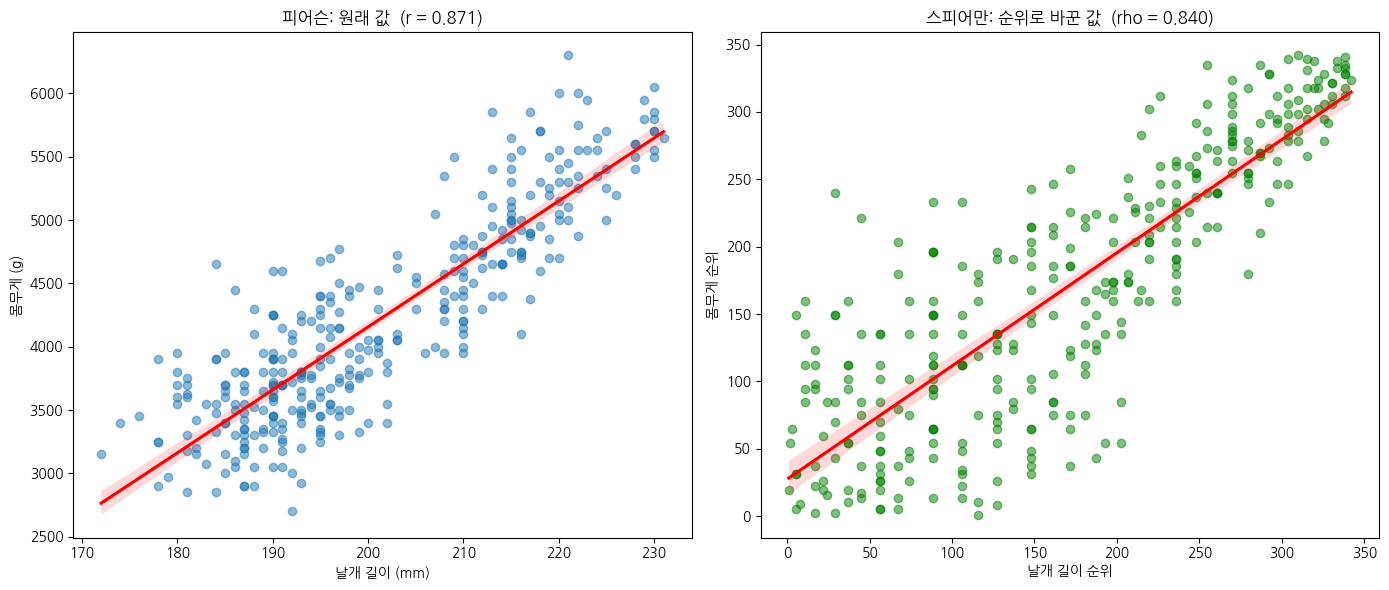

In [11]:
import os, platform, urllib.request
import numpy as np, seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from scipy import stats

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

penguins = sns.load_dataset('penguins')
df_corr = penguins[['flipper_length_mm', 'body_mass_g']].dropna()
x, y = df_corr['flipper_length_mm'], df_corr['body_mass_g']
n = len(x)
r, p_value = stats.pearsonr(x, y)
rho, p_spear = stats.spearmanr(x, y)

# [1] 피어슨 공식 + 값 대입
dx, dy = x - x.mean(), y - y.mean()
Sxy, Sxx, Syy = (dx*dy).sum(), (dx**2).sum(), (dy**2).sum()
print("[1] 피어슨 r = Σ(x-x̄)(y-ȳ) / √[Σ(x-x̄)² · Σ(y-ȳ)²]")
print(f"    x̄ = {x.mean():.2f},  ȳ = {y.mean():.2f},  n = {n}")
print(f"    r = {Sxy:,.0f} / √({Sxx:,.0f} × {Syy:,.0f})")
print(f"      = {Sxy:,.0f} / {np.sqrt(Sxx*Syy):,.0f} = {Sxy/np.sqrt(Sxx*Syy):.4f}")
print(f"    scipy 결과: r = {r:.4f}\n")

# [2] 스피어만 공식 + 값 대입
rx, ry = x.rank(), y.rank()
d2 = ((rx - ry)**2).sum()
rho_simple = 1 - 6*d2 / (n*(n**2 - 1))
print("[2] 스피어만 ρ = 1 - 6Σd² / [n(n²-1)]   (d = 두 순위의 차)")
print(f"    ρ = 1 - 6 × {d2:,.1f} / [{n} × ({n}² - 1)]")
print(f"      = 1 - {6*d2:,.0f} / {n*(n**2-1):,} = {rho_simple:.4f}")
print(f"    순위에 피어슨 적용(동순위 보정): ρ = {rx.corr(ry):.4f}")
print(f"    scipy 결과: rho = {rho:.4f}")
print("    -> 같은 값(동순위)이 많아 간편식과 약간 차이, scipy는 보정값 사용\n")

# [3] p-값 계산 (t 통계량)
t = r*np.sqrt(n-2) / np.sqrt(1 - r**2)
print("[3] 피어슨 검정 t = r√(n-2) / √(1-r²)")
print(f"    t = {r:.4f} × √{n-2} / √(1 - {r:.4f}²) = {t:.2f}")
print(f"    자유도 {n-2}에서 p = {2*stats.t.sf(abs(t), n-2):.2e}  (scipy: {p_value:.2e})\n")

# [4] 비교
print(f"[4] 피어슨 r = {r:.4f},  스피어만 rho = {rho:.4f},  차이 = {rho-r:+.4f}")
print("    -> 둘 다 강한 양(+)의 상관, 정규성이 깨져도 결론은 같다.")

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.regplot(x=x, y=y, ax=ax[0], scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
ax[0].set_title(f'피어슨: 원래 값  (r = {r:.3f})')
ax[0].set_xlabel('날개 길이 (mm)'); ax[0].set_ylabel('몸무게 (g)')
sns.regplot(x=rx, y=ry, ax=ax[1], color='green', scatter_kws={'alpha': 0.5},
            line_kws={'color': 'red'})
ax[1].set_title(f'스피어만: 순위로 바꾼 값  (rho = {rho:.3f})')
ax[1].set_xlabel('날개 길이 순위'); ax[1].set_ylabel('몸무게 순위')
plt.tight_layout(); plt.show()

### Q4 · 세 결과를 종합해 관계를 문장으로 정리해 봅시다

- Q1~Q3의 결과를 근거로, 오른쪽 빈칸을 채워 관계를 정리하세요.

- 숫자만 적지 말고 **그 숫자가 뜻하는 바**를 함께 쓰세요.

# 문제 2 · Q4
# 정규성 검정 결과 (피어슨의 전제가 지켜졌나요?):
   날개 길이 p = 3.54e-09, 몸무게 p = 3.68e-08 -> 둘 다 정규성 기각
   -> 피어슨의 정규성 전제는 지켜지지 않았다.
# 피어슨 r 값과 p-값:
   r = 0.8712, p = 4.37e-107 -> 통계적으로 유의하다.
# 스피어만 ρ 값:
   ρ = 0.8400 -> 정규성 가정 없이도 피어슨과 거의 같은 값.
# 부호(+/-)가 뜻하는 관계의 방향:
   양(+) -> 날개가 길수록 몸무게도 무거워지는 같은 방향의 관계.
# 절대값의 크기가 뜻하는 관계의 강도:
   |r| = 0.87, |ρ| = 0.84 -> 0.7 이상으로 강한 상관.


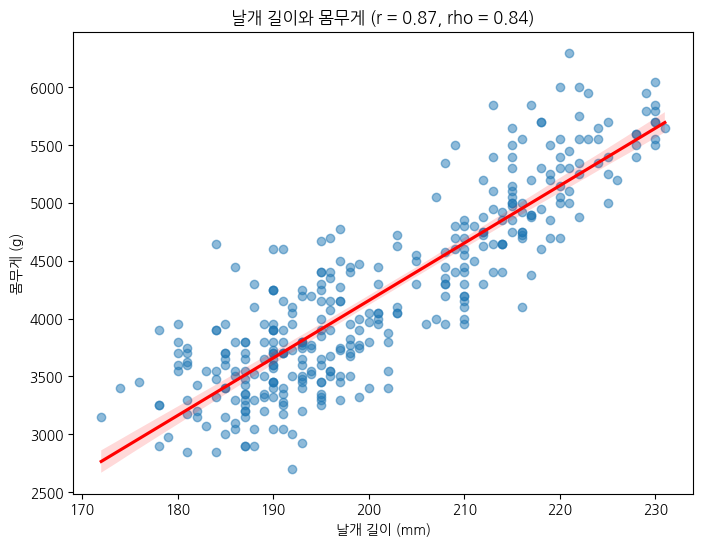

In [12]:
# 문제 2 · Q4
# 정규성 검정 결과 (피어슨의 전제가 지켜졌나요?):
#   날개 길이 p = 3.54e-09, 몸무게 p = 3.68e-08로 둘 다 0.05보다 작아 정규성 기각.
#   -> 피어슨의 정규성 전제는 지켜지지 않았다.
# 피어슨 r 값과 p-값:
#   r = 0.8712, p = 4.37e-107 -> p < 0.05로 통계적으로 유의하다.
# 스피어만 ρ 값:
#   ρ = 0.8400 -> 정규성 가정이 필요 없는 방법으로도 피어슨과 거의 같은 값.
# 부호(+/-)가 뜻하는 관계의 방향:
#   양(+) -> 날개가 길수록 몸무게도 무거워지는 같은 방향의 관계.
# 절대값의 크기가 뜻하는 관계의 강도:
#   |r| = 0.87, |ρ| = 0.84로 0.7 이상 -> 강한 상관관계.

import os, platform, urllib.request
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from scipy import stats

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

penguins = sns.load_dataset('penguins')
df_corr = penguins[['flipper_length_mm', 'body_mass_g']].dropna()
x, y = df_corr['flipper_length_mm'], df_corr['body_mass_g']
_, p1 = stats.shapiro(x)
_, p2 = stats.shapiro(y)
r, p_value = stats.pearsonr(x, y)
rho, _ = stats.spearmanr(x, y)

print("# 문제 2 · Q4")
print("# 정규성 검정 결과 (피어슨의 전제가 지켜졌나요?):")
print(f"   날개 길이 p = {p1:.2e}, 몸무게 p = {p2:.2e} -> 둘 다 정규성 기각")
print("   -> 피어슨의 정규성 전제는 지켜지지 않았다.")
print("# 피어슨 r 값과 p-값:")
print(f"   r = {r:.4f}, p = {p_value:.2e} -> 통계적으로 유의하다.")
print("# 스피어만 ρ 값:")
print(f"   ρ = {rho:.4f} -> 정규성 가정 없이도 피어슨과 거의 같은 값.")
print("# 부호(+/-)가 뜻하는 관계의 방향:")
print("   양(+) -> 날개가 길수록 몸무게도 무거워지는 같은 방향의 관계.")
print("# 절대값의 크기가 뜻하는 관계의 강도:")
print(f"   |r| = {abs(r):.2f}, |ρ| = {abs(rho):.2f} -> 0.7 이상으로 강한 상관.")

plt.figure(figsize=(8, 6))
sns.regplot(x=x, y=y, scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
plt.title(f'날개 길이와 몸무게 (r = {r:.2f}, rho = {rho:.2f})')
plt.xlabel('날개 길이 (mm)'); plt.ylabel('몸무게 (g)')
plt.show()

### 💬 정리 · 결과를 말로 설명해 보기

- Q1에서 정규성이 기각되었습니다. 그렇다면 피어슨 상관계수를 쓰면 안 되는 걸까요? Q2와 Q3의 값을 비교해서 판단해 보세요.

- 피어슨과 스피어만이 비슷하게 나왔다는 것은 무엇을 뜻할까요? 만약 두 값이 크게 달랐다면 어떤 상황을 의심해야 할까요?

- Q2의 p-값은 무엇에 대한 검정인가요? "상관계수가 크다"와 "상관계수가 유의하다"는 같은 말인가요?

- '날개가 길어지는 것이 몸무게를 무겁게 만드는 **원인**이다'라고 결론 내릴 수 있을까요? **교란변수 / 역인과 / 우연** 세 가지로 나누어 설명해 보세요.

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 정규성이 깨졌을 때 확인할 것은 "쓰면 안 되나"가 아니라 **"결론이 바뀌는가"**입니다. 두 계수가 거의 같다면 전제 위배의 영향이 작다는 뜻이고, 크게 다르면 이상치나 비선형을 의심합니다.

- p-값은 관계의 **크기**가 아니라 **존재**에 대한 답입니다. 표본이 커지면 아주 작은 상관도 유의해집니다 — 두 질문을 분리해서 답해 보세요.

- 인과를 부정하는 세 갈래를 이 데이터에 대입해 보세요. 교란변수 후보는 문제 1에서 이미 만났습니다.

</details>

1. 정규성이 기각됐으면 피어슨을 쓰면 안 될까?
   피어슨 r = 0.87, 스피어만 ρ = 0.84로 거의 같다.
   정규성은 주로 p-값 계산의 전제이고, n = 342로 커서 영향이 작다.
   정규성이 필요 없는 스피어만도 같은 결론 -> 피어슨을 써도 무방하다.
   (단, 스피어만을 함께 보고하는 것이 안전하다)

2. 두 값이 비슷하다는 뜻은?
   관계가 대체로 직선이고, 몇몇 극단값이 결과를 좌우하지 않는다는 뜻.
   크게 달랐다면 의심할 것: 이상치, 곡선 관계, 집단(덩어리) 구조.

3. Q2의 p-값은 무엇에 대한 검정인가?
   H0 '모집단 상관계수 = 0'에 대한 검정 -> 상관이 0이 아니라는 증거.
   n = 342이면 |r| > 0.106만 넘어도 유의하다.
   즉 '유의하다'(0이 아니다) ≠ '크다'(강하다). 크기는 |r|로 판단한다.
   여기서는 p = 4.4e-107로 유의하고, |r| = 0.87로 크기도 크다.

4. '날개가 길어서 몸무게가 무겁다'고 결론 낼 수 있을까? -> 없다.
   ① 교란변수: 종·몸집이 둘 다를 키운다. 종별로 보면 상관이 약해진다
      (Adelie 0.47, Chinstrap 0.64, Gentoo 0.70 vs 전체 0.87)
   ② 역인과: 몸이 무거워서 날개가 길게 자란 것일 수도 있다.
      상관계수는 방향을 알려주지 않는다.
   ③ 우연: p = 4.4e-107로 우연일 가능성은 매우 낮다.
      하지만 우연을 배제해도 ①②가 남아 인과는 주장할 수 없다.


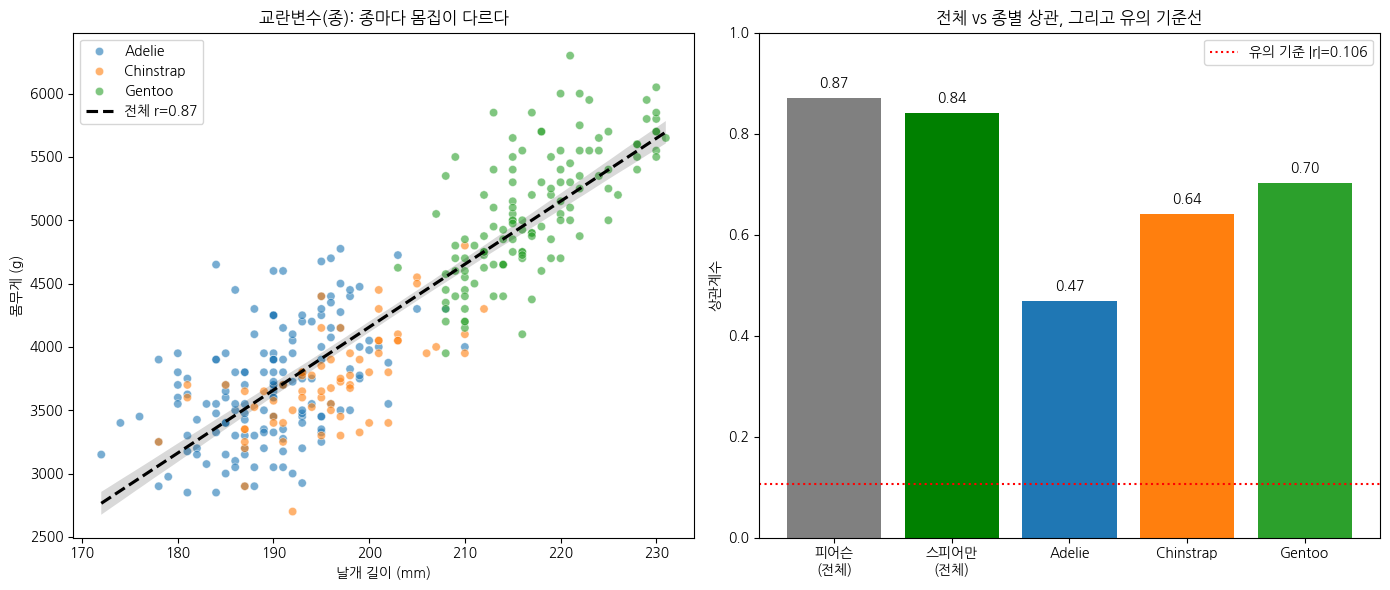

In [13]:
import os, platform, urllib.request
import numpy as np, seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from scipy import stats

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

penguins = sns.load_dataset('penguins')
A, B = 'flipper_length_mm', 'body_mass_g'
df = penguins[[A, B, 'species']].dropna()
x, y, n = df[A], df[B], len(df)
r, p_value = stats.pearsonr(x, y)
rho, p_s = stats.spearmanr(x, y)
r_sp = {k: stats.pearsonr(g[A], g[B])[0] for k, g in df.groupby('species')}
t05 = stats.t.ppf(0.975, n - 2)
r_crit = t05 / np.sqrt(t05**2 + n - 2)

print("1. 정규성이 기각됐으면 피어슨을 쓰면 안 될까?")
print(f"   피어슨 r = {r:.2f}, 스피어만 ρ = {rho:.2f}로 거의 같다.")
print("   정규성은 주로 p-값 계산의 전제이고, n = 342로 커서 영향이 작다.")
print("   정규성이 필요 없는 스피어만도 같은 결론 -> 피어슨을 써도 무방하다.")
print("   (단, 스피어만을 함께 보고하는 것이 안전하다)\n")

print("2. 두 값이 비슷하다는 뜻은?")
print("   관계가 대체로 직선이고, 몇몇 극단값이 결과를 좌우하지 않는다는 뜻.")
print("   크게 달랐다면 의심할 것: 이상치, 곡선 관계, 집단(덩어리) 구조.\n")

print("3. Q2의 p-값은 무엇에 대한 검정인가?")
print("   H0 '모집단 상관계수 = 0'에 대한 검정 -> 상관이 0이 아니라는 증거.")
print(f"   n = {n}이면 |r| > {r_crit:.3f}만 넘어도 유의하다.")
print("   즉 '유의하다'(0이 아니다) ≠ '크다'(강하다). 크기는 |r|로 판단한다.")
print(f"   여기서는 p = {p_value:.1e}로 유의하고, |r| = {r:.2f}로 크기도 크다.\n")

print("4. '날개가 길어서 몸무게가 무겁다'고 결론 낼 수 있을까? -> 없다.")
print("   ① 교란변수: 종·몸집이 둘 다를 키운다. 종별로 보면 상관이 약해진다")
print("      (" + ", ".join(f"{k} {v:.2f}" for k, v in r_sp.items()) + f" vs 전체 {r:.2f})")
print("   ② 역인과: 몸이 무거워서 날개가 길게 자란 것일 수도 있다.")
print("      상관계수는 방향을 알려주지 않는다.")
print(f"   ③ 우연: p = {p_value:.1e}로 우연일 가능성은 매우 낮다.")
print("      하지만 우연을 배제해도 ①②가 남아 인과는 주장할 수 없다.")

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.scatterplot(data=df, x=A, y=B, hue='species', alpha=0.6, ax=ax[0])
sns.regplot(data=df, x=A, y=B, scatter=False, color='black',
            line_kws={'ls': '--'}, ax=ax[0], label=f'전체 r={r:.2f}')
ax[0].set_title('교란변수(종): 종마다 몸집이 다르다')
ax[0].set_xlabel('날개 길이 (mm)'); ax[0].set_ylabel('몸무게 (g)'); ax[0].legend()
labels = ['피어슨\n(전체)', '스피어만\n(전체)'] + list(r_sp)
vals = [r, rho] + list(r_sp.values())
ax[1].bar(labels, vals, color=['gray', 'green', '#1f77b4', '#ff7f0e', '#2ca02c'])
ax[1].axhline(r_crit, color='red', ls=':', label=f'유의 기준 |r|={r_crit:.3f}')
for i, v in enumerate(vals): ax[1].text(i, v + 0.02, f'{v:.2f}', ha='center')
ax[1].set_ylim(0, 1); ax[1].set_ylabel('상관계수')
ax[1].set_title('전체 vs 종별 상관, 그리고 유의 기준선'); ax[1].legend()
plt.tight_layout(); plt.show()

## 문제 3 · 그 관계를 하나의 식으로 만들 수 있을까?

`난이도 중` · `예상 25분`

**📖 상황**

- 상관계수는 "관계가 얼마나 **강한가**"만 알려주고, "날개가 1mm 길면 몸무게가 **몇 g** 늘어나는가"는
  말해주지 않습니다. 그 답을 주는 것이 **선형회귀(Linear Regression)**입니다.

- 흩어진 점들을 가장 잘 가로지르는 직선 `y = a + bx`를 찾아 관계를 하나의 **식**으로 표현합니다.
  `a`(절편)는 x가 0일 때의 예측값, `b`(기울기)는 **x가 1 늘 때 y가 평균적으로 변하는 양**입니다.

- 그런데 상관과 회귀는 **서로 남이 아닙니다.** 문제 2에서 구한 `r`과
  이번에 구할 기울기·결정계수 사이에는 정확한 관계식이 성립합니다.

**🎯 이 문제로 배우는 것**

- 회귀식을 적합·해석하고, **상관과 회귀가 한 뿌리임을 숫자로 확인**합니다.

In [14]:
# 문제 3 · 데이터 준비 — 실행만 하세요
penguins_cleaned = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])

print("분석에 사용할 데이터:", len(penguins_cleaned), "행")
print("문제 2의 df_corr과 동일한가?:", len(penguins_cleaned) == len(df_corr))

분석에 사용할 데이터: 342 행
문제 2의 df_corr과 동일한가?: True


### Q1 · 단순회귀 모델을 적합해 봅시다

- **날개 길이(설명변수) → 몸무게(반응변수)** 회귀 모델을 적합하세요.

- 적합한 모델은 반드시 `model`이라는 이름으로 저장하세요. **문제 4·5에서 이어서 사용합니다.**

- `💡 힌트` `model = smf.ols(formula='body_mass_g ~ flipper_length_mm', data=...).fit()`

분석에 사용할 데이터: 342 행
문제 2의 df_corr과 동일한가?: True 

                            OLS Regression Results                            
Dep. Variable:            body_mass_g   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.758
Method:                 Least Squares   F-statistic:                     1071.
Date:                Wed, 04 Nov 2026   Prob (F-statistic):          4.37e-107
Time:                        08:21:18   Log-Likelihood:                -2528.4
No. Observations:                 342   AIC:                             5061.
Df Residuals:                     340   BIC:                             5069.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------

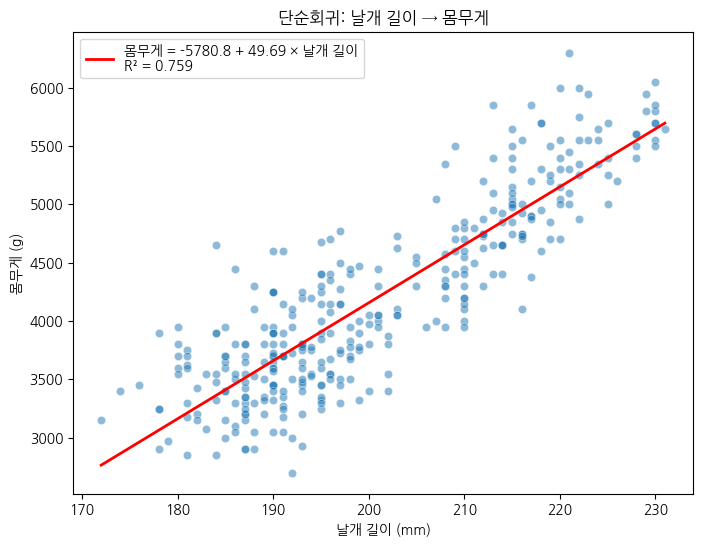

In [15]:
import os, platform, urllib.request
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.formula.api as smf

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

# 데이터 준비
penguins = sns.load_dataset('penguins')
df_corr = penguins[['flipper_length_mm', 'body_mass_g']].dropna()
penguins_cleaned = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])
print("분석에 사용할 데이터:", len(penguins_cleaned), "행")
print("문제 2의 df_corr과 동일한가?:", len(penguins_cleaned) == len(df_corr), "\n")

# Q1 · 단순회귀: 날개 길이(X) -> 몸무게(Y)
model = smf.ols(formula='body_mass_g ~ flipper_length_mm',
                data=penguins_cleaned).fit()
print(model.summary(), "\n")

b0 = model.params['Intercept']
b1 = model.params['flipper_length_mm']
print("[회귀식] 몸무게 = b0 + b1 × 날개 길이")
print(f"         몸무게 = {b0:.2f} + {b1:.2f} × 날개 길이")
print(f"-> 날개가 1mm 길어질 때 몸무게가 평균 {b1:.1f}g 무거워진다.")
print(f"-> b1의 p-값 = {model.pvalues['flipper_length_mm']:.2e} (유의함)")
print(f"-> R² = {model.rsquared:.3f}: 몸무게 변동의 약 {model.rsquared*100:.0f}%를 날개 길이로 설명")

plt.figure(figsize=(8, 6))
sns.scatterplot(data=penguins_cleaned, x='flipper_length_mm', y='body_mass_g', alpha=0.5)
xs = penguins_cleaned['flipper_length_mm'].sort_values()
plt.plot(xs, b0 + b1 * xs, color='red', lw=2,
         label=f'몸무게 = {b0:.1f} + {b1:.2f} × 날개 길이\nR² = {model.rsquared:.3f}')
plt.title('단순회귀: 날개 길이 → 몸무게')
plt.xlabel('날개 길이 (mm)'); plt.ylabel('몸무게 (g)')
plt.legend(); plt.show()

### Q2 · 분석 결과표를 출력해 봅시다

- 적합한 모델의 요약 결과표를 출력하세요.

- `coef`, `P>|t|`, `R-squared` 열이 각각 어디에 있는지 눈으로 찾아 두세요. 다음 문제들에서 계속 씁니다.

- `💡 힌트` 모델 객체의 `.summary()` 메소드를 사용하세요.

                            OLS Regression Results                            
Dep. Variable:            body_mass_g   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.758
Method:                 Least Squares   F-statistic:                     1071.
Date:                Wed, 04 Nov 2026   Prob (F-statistic):          4.37e-107
Time:                        08:21:23   Log-Likelihood:                -2528.4
No. Observations:                 342   AIC:                             5061.
Df Residuals:                     340   BIC:                             5069.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept         -5780.8314    305.81

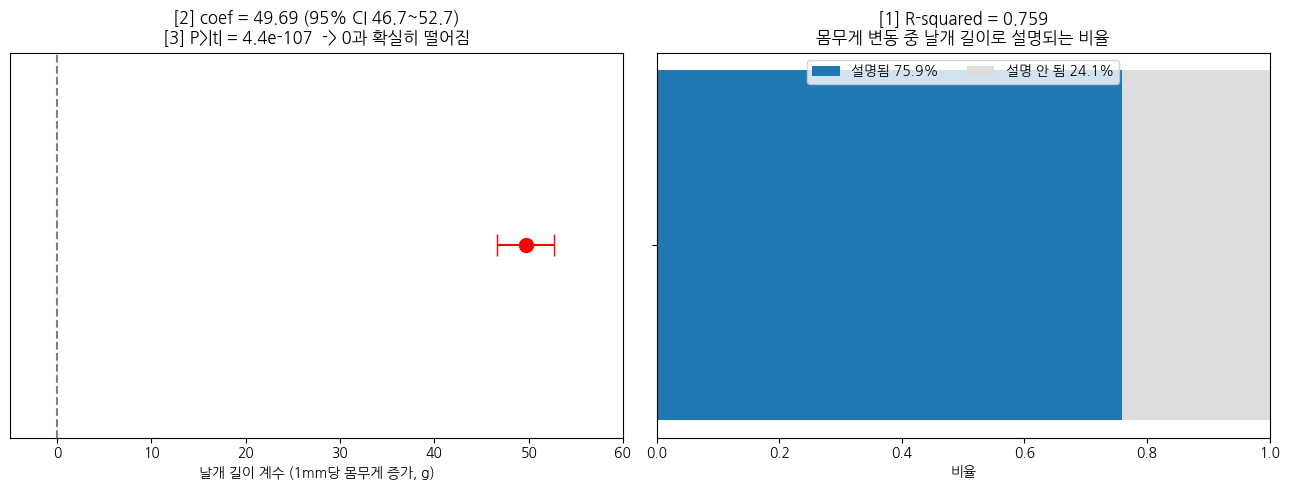

In [16]:
import os, platform, urllib.request
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.formula.api as smf

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

penguins = sns.load_dataset('penguins')
penguins_cleaned = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])
model = smf.ols(formula='body_mass_g ~ flipper_length_mm',
                data=penguins_cleaned).fit()

# Q2-1 · 요약 결과표 출력
print(model.summary())

# Q2-2 · coef, P>|t|, R-squared 위치와 값
X = 'flipper_length_mm'
print("\n[결과표에서 찾을 세 가지]")
print("① R-squared : 표 맨 위 오른쪽 블록, 첫 줄")
print(f"   R-squared = {model.rsquared:.3f}")
print("② coef      : 가운데 블록의 'coef' 열")
print(f"   Intercept = {model.params['Intercept']:.2f}")
print(f"   {X} = {model.params[X]:.2f}")
print("③ P>|t|     : 가운데 블록의 'P>|t|' 열 (coef 오른쪽 세 번째 칸)")
print(f"   Intercept = {model.pvalues['Intercept']:.2e}")
print(f"   {X} = {model.pvalues[X]:.2e}")
print("   (표에는 0.000으로 보이지만 실제로는 0이 아닌 아주 작은 값)")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
lo, hi = model.conf_int().loc[X]
ax[0].errorbar(model.params[X], 0, xerr=[[model.params[X] - lo], [hi - model.params[X]]],
               fmt='o', color='red', capsize=8, ms=10)
ax[0].axvline(0, color='gray', ls='--')
ax[0].set_yticks([]); ax[0].set_xlim(-5, 60)
ax[0].set_title(f'[2] coef = {model.params[X]:.2f} (95% CI {lo:.1f}~{hi:.1f})\n'
                f'[3] P>|t| = {model.pvalues[X]:.1e}  -> 0과 확실히 떨어짐')
ax[0].set_xlabel('날개 길이 계수 (1mm당 몸무게 증가, g)')
r2 = model.rsquared
ax[1].barh([''], [r2], color='#1f77b4', label=f'설명됨 {r2:.1%}')
ax[1].barh([''], [1 - r2], left=[r2], color='#dddddd', label=f'설명 안 됨 {1-r2:.1%}')
ax[1].set_xlim(0, 1); ax[1].legend(loc='upper center', ncol=2)
ax[1].set_title(f'[1] R-squared = {r2:.3f}\n몸무게 변동 중 날개 길이로 설명되는 비율')
ax[1].set_xlabel('비율')
plt.tight_layout(); plt.show()

### Q3 · 회귀식을 완성해 봅시다

- Q2의 결과표에서 **절편**과 **기울기**를 찾아 오른쪽 빈칸을 채우세요.

- 숫자를 옮겨 적은 뒤, 완성된 식을 한 줄로 써 보세요.

# 문제 3 · Q3
# 절편(a) 값: -5780.83
# 기울기(b) 값: 49.69
# 완성된 회귀식 → 몸무게(g) = -5780.83 + 49.69 × 날개길이(mm)

-> 기울기: 날개가 1mm 길어질 때마다 몸무게가 평균 49.7g 늘어난다.
-> 절편: 날개 0mm일 때의 값이라 현실적 의미는 없고, 선의 높이를 맞추는 값이다.
-> 예) 날개 200mm 펭귄의 예상 몸무게 = -5780.83 + 49.69 × 200 = 4156g


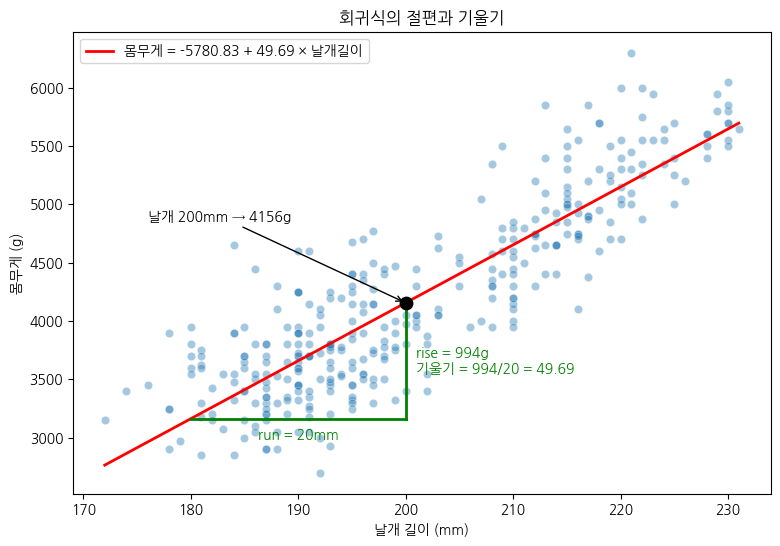

In [17]:
# 문제 3 · Q3
# 절편(a) 값: -5780.83
# 기울기(b) 값: 49.69
# 완성된 회귀식 → 몸무게(g) = -5780.83 + 49.69 × 날개길이(mm)

import os, platform, urllib.request
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.formula.api as smf

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

penguins = sns.load_dataset('penguins')
penguins_cleaned = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])
model = smf.ols(formula='body_mass_g ~ flipper_length_mm',
                data=penguins_cleaned).fit()

a = model.params['Intercept']
b = model.params['flipper_length_mm']

print("# 문제 3 · Q3")
print(f"# 절편(a) 값: {a:.2f}")
print(f"# 기울기(b) 값: {b:.2f}")
print(f"# 완성된 회귀식 → 몸무게(g) = {a:.2f} + {b:.2f} × 날개길이(mm)")
print()
print(f"-> 기울기: 날개가 1mm 길어질 때마다 몸무게가 평균 {b:.1f}g 늘어난다.")
print("-> 절편: 날개 0mm일 때의 값이라 현실적 의미는 없고, 선의 높이를 맞추는 값이다.")
print(f"-> 예) 날개 200mm 펭귄의 예상 몸무게 = {a:.2f} + {b:.2f} × 200 = {a + b*200:.0f}g")

d = penguins_cleaned
plt.figure(figsize=(9, 6))
sns.scatterplot(data=d, x='flipper_length_mm', y='body_mass_g', alpha=0.4)
xs = d['flipper_length_mm'].sort_values()
plt.plot(xs, a + b * xs, color='red', lw=2,
         label=f'몸무게 = {a:.2f} + {b:.2f} × 날개길이')
x0, dx = 180, 20
y0, y1 = a + b * x0, a + b * (x0 + dx)
plt.plot([x0, x0 + dx], [y0, y0], 'g-', lw=2)
plt.plot([x0 + dx, x0 + dx], [y0, y1], 'g-', lw=2)
plt.text(x0 + dx/2, y0 - 180, f'run = {dx}mm', ha='center', color='green')
plt.text(x0 + dx + 1, (y0 + y1)/2, f'rise = {b*dx:.0f}g\n기울기 = {b*dx:.0f}/{dx} = {b:.2f}',
         color='green', va='center')
plt.scatter([200], [a + b*200], color='black', s=80, zorder=5)
plt.annotate(f'날개 200mm → {a + b*200:.0f}g', (200, a + b*200),
             xytext=(176, a + b*200 + 700), arrowprops=dict(arrowstyle='->'))
plt.title('회귀식의 절편과 기울기')
plt.xlabel('날개 길이 (mm)'); plt.ylabel('몸무게 (g)')
plt.legend(loc='upper left'); plt.show()

### Q4 · 회귀식으로 예측해 봅시다

- 날개 길이가 평균보다 **10mm 더 긴** 펭귄은, 평균적인 펭귄보다 몸무게가 몇 g 더 무거울까요?

- 계산 결과를 단위(g)와 함께 출력하세요.

- `💡 힌트` 기울기 × 10

Q4 · 회귀식으로 예측하기

회귀식: 몸무게 = -5780.83 + 49.69 × 날개길이
평균 날개 길이: 200.92 mm

[방법 1] 예측값 두 개를 빼기
  평균 펭귄   (200.92mm): 4201.75 g
  +10mm 펭귄 (210.92mm): 4698.61 g
  차이 = 4698.61 - 4201.75 = 496.86 g

[방법 2] 기울기 × 10
  49.69 × 10 = 496.86 g

-> 답: 평균보다 날개가 10mm 긴 펭귄은 약 496.9 g 더 무겁다.
-> 절편은 두 예측값에서 똑같이 빠지므로, 차이는 기울기만으로 결정된다.


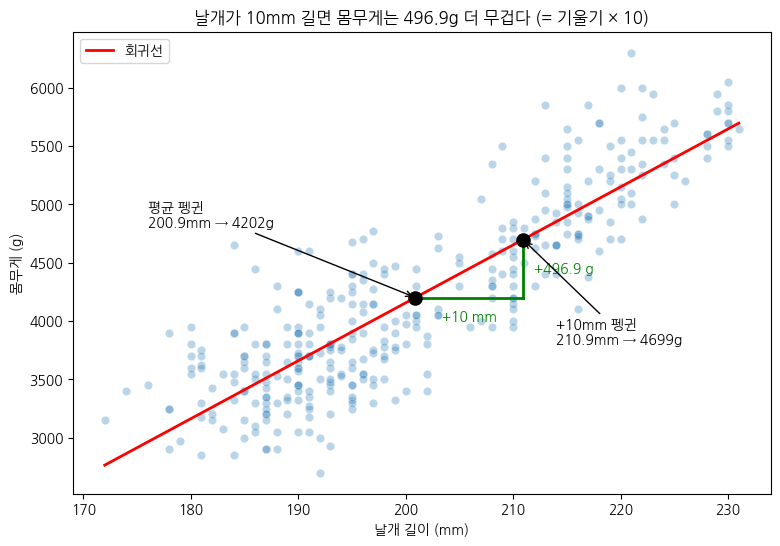

In [18]:
import os, platform, urllib.request
import pandas as pd, seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.formula.api as smf

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

penguins = sns.load_dataset('penguins')
penguins_cleaned = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])
model = smf.ols(formula='body_mass_g ~ flipper_length_mm',
                data=penguins_cleaned).fit()
a = model.params['Intercept']
b = model.params['flipper_length_mm']

# 평균 펭귄 vs 평균보다 10mm 긴 펭귄
x_mean = penguins_cleaned['flipper_length_mm'].mean()
new = pd.DataFrame({'flipper_length_mm': [x_mean, x_mean + 10]})
y_pred = model.predict(new)
diff = y_pred[1] - y_pred[0]

print("Q4 · 회귀식으로 예측하기\n")
print(f"회귀식: 몸무게 = {a:.2f} + {b:.2f} × 날개길이")
print(f"평균 날개 길이: {x_mean:.2f} mm\n")
print(f"[방법 1] 예측값 두 개를 빼기")
print(f"  평균 펭귄   ({x_mean:.2f}mm): {y_pred[0]:.2f} g")
print(f"  +10mm 펭귄 ({x_mean + 10:.2f}mm): {y_pred[1]:.2f} g")
print(f"  차이 = {y_pred[1]:.2f} - {y_pred[0]:.2f} = {diff:.2f} g\n")
print(f"[방법 2] 기울기 × 10")
print(f"  {b:.2f} × 10 = {b * 10:.2f} g\n")
print(f"-> 답: 평균보다 날개가 10mm 긴 펭귄은 약 {diff:.1f} g 더 무겁다.")
print("-> 절편은 두 예측값에서 똑같이 빠지므로, 차이는 기울기만으로 결정된다.")

d = penguins_cleaned
plt.figure(figsize=(9, 6))
sns.scatterplot(data=d, x='flipper_length_mm', y='body_mass_g', alpha=0.3)
xs = d['flipper_length_mm'].sort_values()
plt.plot(xs, a + b * xs, color='red', lw=2, label='회귀선')
x1, x2 = x_mean, x_mean + 10
y1, y2 = y_pred[0], y_pred[1]
plt.scatter([x1, x2], [y1, y2], color='black', s=90, zorder=5)
plt.plot([x1, x2], [y1, y1], 'g-', lw=2)
plt.plot([x2, x2], [y1, y2], 'g-', lw=2)
plt.text((x1 + x2)/2, y1 - 200, '+10 mm', ha='center', color='green')
plt.text(x2 + 1, (y1 + y2)/2, f'+{diff:.1f} g', color='green', va='center')
plt.annotate(f'평균 펭귄\n{x1:.1f}mm → {y1:.0f}g', (x1, y1),
             xytext=(176, y1 + 600), arrowprops=dict(arrowstyle='->'))
plt.annotate(f'+10mm 펭귄\n{x2:.1f}mm → {y2:.0f}g', (x2, y2),
             xytext=(214, y2 - 900), arrowprops=dict(arrowstyle='->'))
plt.title(f'날개가 10mm 길면 몸무게는 {diff:.1f}g 더 무겁다 (= 기울기 × 10)')
plt.xlabel('날개 길이 (mm)'); plt.ylabel('몸무게 (g)')
plt.legend(loc='upper left'); plt.show()

### Q5 · 상관과 회귀를 잇는 두 관계식을 확인해 봅시다

- 다음 두 식이 실제로 성립하는지 **숫자로** 확인하세요.
  - ① 기울기 = `r` × (y의 표준편차 / x의 표준편차)
  - ② 결정계수 `R²` = `r²` _(단순회귀에서만 성립)_

- 좌변과 우변을 **나란히 출력**해 두 값이 일치하는지 눈으로 확인하세요.

- `💡 힌트` 문제 2 Q2의 `r`을 사용합니다. 표준편차는 `.std(ddof=1)`, 모델의 R²는 `model.rsquared`입니다.

Q5 · 상관과 회귀를 잇는 두 관계식

① 기울기 = r × (sy / sx)
   대입: 0.8712 × (801.95 / 14.06) = 49.6856
   좌변 (model 기울기)  = 49.6856
   우변 (r × sy / sx)  = 49.6856
   -> 일치하는가? True

② R² = r²  (단순회귀에서만 성립)
   대입: 0.8712² = 0.7590
   좌변 (model.rsquared) = 0.7590
   우변 (r²)             = 0.7590
   -> 일치하는가? True

-> 상관계수 r에 단위(sy/sx)를 붙이면 회귀 기울기가 되고,
   r을 제곱하면 회귀가 설명하는 비율(R²)이 된다.


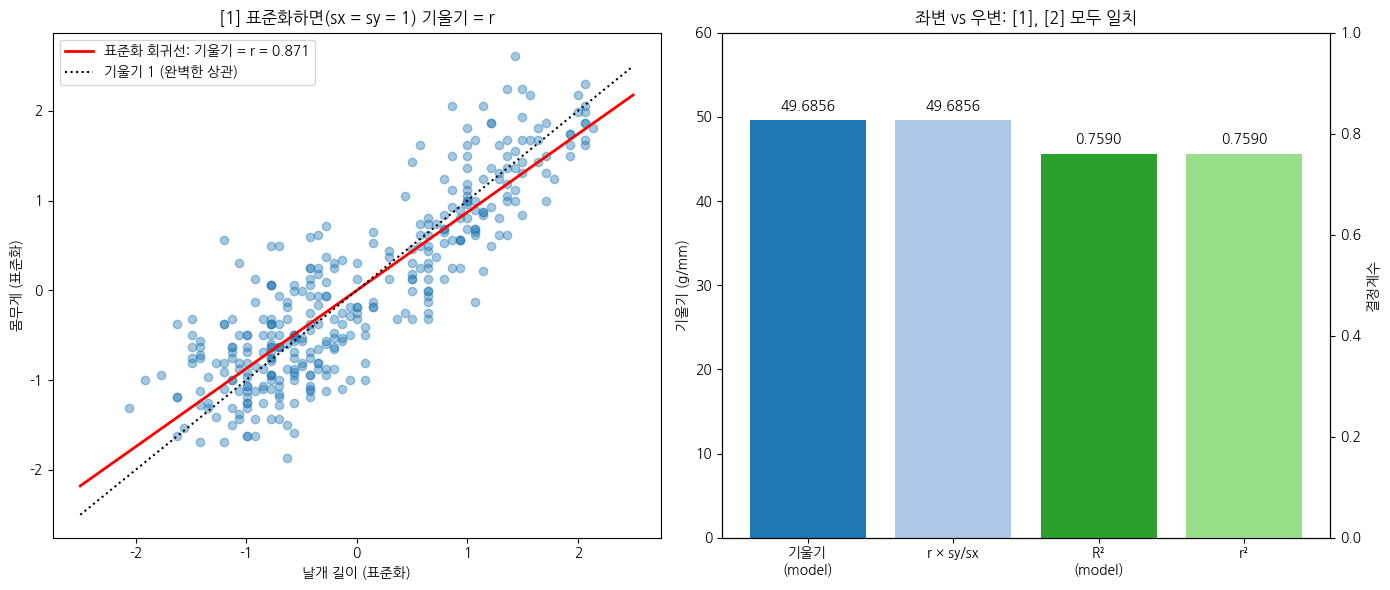

In [19]:
import os, platform, urllib.request
import numpy as np, seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.formula.api as smf
from scipy import stats

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

penguins = sns.load_dataset('penguins')
penguins_cleaned = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])
x = penguins_cleaned['flipper_length_mm']
y = penguins_cleaned['body_mass_g']

r, p_value = stats.pearsonr(x, y)                       # 문제 2 Q2
model = smf.ols('body_mass_g ~ flipper_length_mm', data=penguins_cleaned).fit()
b = model.params['flipper_length_mm']
sx, sy = x.std(ddof=1), y.std(ddof=1)

print("Q5 · 상관과 회귀를 잇는 두 관계식\n")
print("① 기울기 = r × (sy / sx)")
print(f"   대입: {r:.4f} × ({sy:.2f} / {sx:.2f}) = {r * sy / sx:.4f}")
print(f"   좌변 (model 기울기)  = {b:.4f}")
print(f"   우변 (r × sy / sx)  = {r * sy / sx:.4f}")
print(f"   -> 일치하는가? {np.isclose(b, r * sy / sx)}\n")

print("② R² = r²  (단순회귀에서만 성립)")
print(f"   대입: {r:.4f}² = {r**2:.4f}")
print(f"   좌변 (model.rsquared) = {model.rsquared:.4f}")
print(f"   우변 (r²)             = {r**2:.4f}")
print(f"   -> 일치하는가? {np.isclose(model.rsquared, r**2)}\n")

print("-> 상관계수 r에 단위(sy/sx)를 붙이면 회귀 기울기가 되고,")
print("   r을 제곱하면 회귀가 설명하는 비율(R²)이 된다.")

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
zx, zy = (x - x.mean()) / sx, (y - y.mean()) / sy
ax[0].scatter(zx, zy, alpha=0.4)
t = np.linspace(-2.5, 2.5, 100)
ax[0].plot(t, r * t, 'r-', lw=2, label=f'표준화 회귀선: 기울기 = r = {r:.3f}')
ax[0].plot(t, t, 'k:', label='기울기 1 (완벽한 상관)')
ax[0].set_title('[1] 표준화하면(sx = sy = 1) 기울기 = r')
ax[0].set_xlabel('날개 길이 (표준화)'); ax[0].set_ylabel('몸무게 (표준화)')
ax[0].legend(loc='upper left')
labels = ['기울기\n(model)', 'r × sy/sx', 'R²\n(model)', 'r²']
vals = [b, r * sy / sx, model.rsquared, r**2]
ax2 = ax[1]; ax3 = ax2.twinx()
ax2.bar(labels[:2], vals[:2], color=['#1f77b4', '#aec7e8'])
ax3.bar(labels[2:], vals[2:], color=['#2ca02c', '#98df8a'])
for i, v in enumerate(vals[:2]): ax2.text(i, v + 1, f'{v:.4f}', ha='center')
for i, v in enumerate(vals[2:]): ax3.text(i + 2, v + 0.02, f'{v:.4f}', ha='center')
ax2.set_ylim(0, 60); ax3.set_ylim(0, 1)
ax2.set_ylabel('기울기 (g/mm)'); ax3.set_ylabel('결정계수')
ax2.set_title('좌변 vs 우변: [1], [2] 모두 일치')
plt.tight_layout(); plt.show()

### 💬 정리 · 결과를 말로 설명해 보기

- 기울기(b) 값을 "날개 길이가 ○○할 때 몸무게가 ○○한다"는 문장으로 풀어 써 보세요.

- 절편(a)이 음수로 나왔습니다. 이 숫자를 "날개 길이가 0mm인 펭귄의 몸무게"로 해석해도 될까요? 왜 그럴까요?

- Q5에서 `R² = r²`을 확인했습니다. 그렇다면 설명변수와 반응변수를 서로 바꿔 분석하면 **기울기**와 **R²**는 각각 같을까요, 다를까요?

- 상관계수 `r`은 단위 없는 −1~1 값이고, 기울기 `b`는 'mm당 g'이라는 단위를 가집니다. 회귀가 상관보다 더 알려주는 것은 무엇인가요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 절편은 **데이터가 존재하는 범위 밖의 값**입니다. 날개 길이 0mm인 펭귄은 우리 데이터에 없습니다 — 회귀식은 관측 범위 안에서만 의미를 갖습니다.

- x와 y를 바꿨을 때를 생각할 때 기준은 **"r은 대칭인가, s_y/s_x는 대칭인가"**입니다. 두 관계식 ①②를 각각 대입해 보면 답이 갈립니다.

- "강도"와 "변화량"의 차이로 정리해 보세요. 보고서에 "1mm당 ○g"을 쓸 수 있는 쪽은 어느 것인가요?

</details>

1. 기울기(b) 해석
   b = 49.69 -> 날개 길이가 1mm 길어질 때 몸무게가 평균 49.7g 증가한다.
   (10mm 길어지면 약 497g 증가)

2. 절편(a)을 '날개 0mm 펭귄의 몸무게'로 해석해도 될까? -> 안 된다.
   a = -5780.83g : 몸무게가 음수인 펭귄은 존재할 수 없다.
   실제 데이터의 날개 길이는 172~231mm 뿐이다.
   0mm는 데이터 범위 밖이라, 직선을 억지로 연장(외삽)한 계산값일 뿐이다.
   절편은 회귀선의 높이를 맞추는 역할만 한다.

3. X와 Y를 바꾸면?
   몸무게 ~ 날개 : 기울기 = 49.6856 g/mm,   R² = 0.7590
   날개 ~ 몸무게 : 기울기 = 0.0153 mm/g,  R² = 0.7590
   -> R²는 같다 (둘 다 r² = 대칭인 r을 제곱한 값).
   -> 기울기는 다르다 (b = r·sy/sx 이므로, 바꾸면 r·sx/sy).
      확인: 1/b = 0.0201 ≠ 0.0153  (역수도 아니다)
      두 기울기의 곱 = 0.7590 = r² = 0.7590

4. 회귀가 상관보다 더 알려주는 것
   r = 0.87 : '관계가 얼마나 강하고 어느 방향인가'만 알려준다 (단위 없음).
   b = 49.69 g/mm : '1mm당 몇 g 변하는가'라는 실제 크기를 알려준다.
   -> 예측 가능: 날개 210mm 펭귄 ≈ 4653g
   -> 방향이 있다: X로 Y를 설명 (상관은 X, Y 대칭)
   -> 다른 변수(종, 성별 등)를 함께 넣어 통제할 수 있다 (다중회귀)


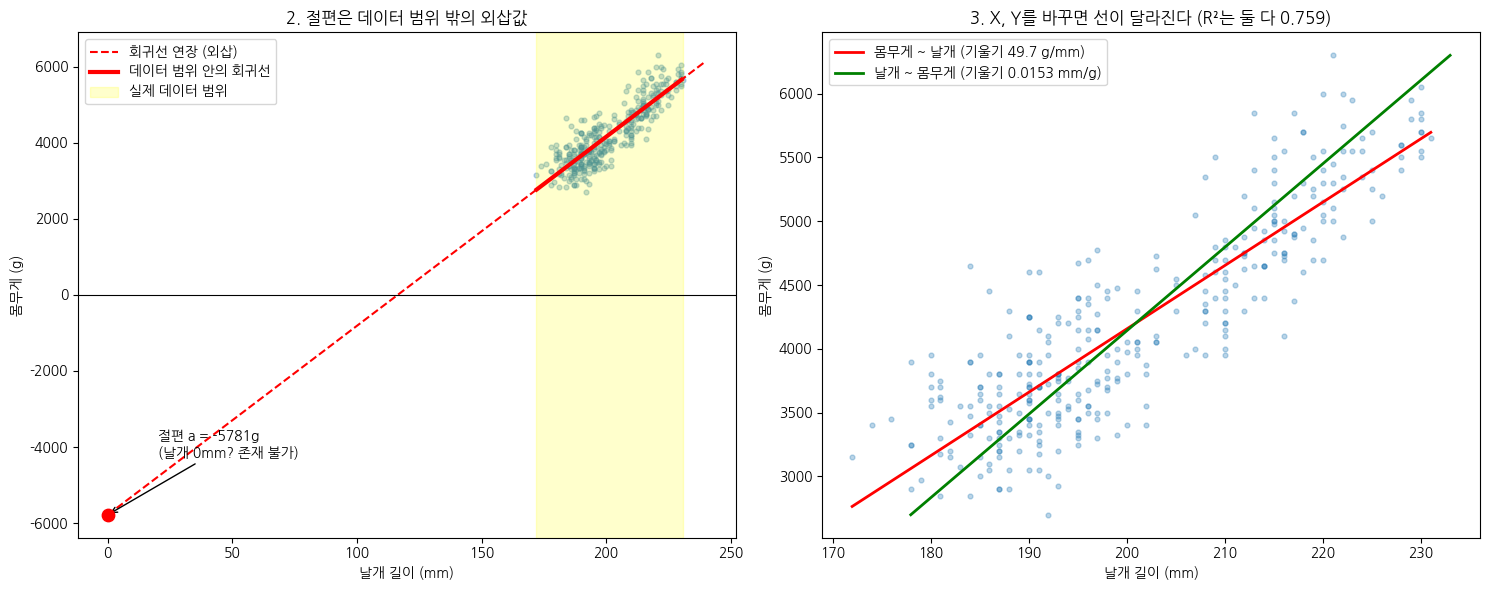

In [20]:
import os, platform, urllib.request
import numpy as np, seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.formula.api as smf
from scipy import stats

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

penguins = sns.load_dataset('penguins')
d = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])
x, y = d['flipper_length_mm'], d['body_mass_g']
model = smf.ols('body_mass_g ~ flipper_length_mm', data=d).fit()
rev = smf.ols('flipper_length_mm ~ body_mass_g', data=d).fit()   # 변수 바꾸기
a, b = model.params
a2, b2 = rev.params
r, _ = stats.pearsonr(x, y)

print("1. 기울기(b) 해석")
print(f"   b = {b:.2f} -> 날개 길이가 1mm 길어질 때 몸무게가 평균 {b:.1f}g 증가한다.")
print(f"   (10mm 길어지면 약 {10*b:.0f}g 증가)\n")

print("2. 절편(a)을 '날개 0mm 펭귄의 몸무게'로 해석해도 될까? -> 안 된다.")
print(f"   a = {a:.2f}g : 몸무게가 음수인 펭귄은 존재할 수 없다.")
print(f"   실제 데이터의 날개 길이는 {x.min():.0f}~{x.max():.0f}mm 뿐이다.")
print("   0mm는 데이터 범위 밖이라, 직선을 억지로 연장(외삽)한 계산값일 뿐이다.")
print("   절편은 회귀선의 높이를 맞추는 역할만 한다.\n")

print("3. X와 Y를 바꾸면?")
print(f"   몸무게 ~ 날개 : 기울기 = {b:.4f} g/mm,   R² = {model.rsquared:.4f}")
print(f"   날개 ~ 몸무게 : 기울기 = {b2:.4f} mm/g,  R² = {rev.rsquared:.4f}")
print("   -> R²는 같다 (둘 다 r² = 대칭인 r을 제곱한 값).")
print("   -> 기울기는 다르다 (b = r·sy/sx 이므로, 바꾸면 r·sx/sy).")
print(f"      확인: 1/b = {1/b:.4f} ≠ {b2:.4f}  (역수도 아니다)")
print(f"      두 기울기의 곱 = {b * b2:.4f} = r² = {r**2:.4f}\n")

print("4. 회귀가 상관보다 더 알려주는 것")
print(f"   r = {r:.2f} : '관계가 얼마나 강하고 어느 방향인가'만 알려준다 (단위 없음).")
print(f"   b = {b:.2f} g/mm : '1mm당 몇 g 변하는가'라는 실제 크기를 알려준다.")
print(f"   -> 예측 가능: 날개 210mm 펭귄 ≈ {a + b*210:.0f}g")
print("   -> 방향이 있다: X로 Y를 설명 (상관은 X, Y 대칭)")
print("   -> 다른 변수(종, 성별 등)를 함께 넣어 통제할 수 있다 (다중회귀)")

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].scatter(x, y, alpha=0.3, s=12)
t = np.linspace(0, 240, 100)
ax[0].plot(t, a + b*t, 'r--', lw=1.5, label='회귀선 연장 (외삽)')
ax[0].plot(t[(t >= x.min()) & (t <= x.max())], a + b*t[(t >= x.min()) & (t <= x.max())],
           'r-', lw=3, label='데이터 범위 안의 회귀선')
ax[0].axvspan(x.min(), x.max(), color='yellow', alpha=0.2, label='실제 데이터 범위')
ax[0].axhline(0, color='black', lw=0.8)
ax[0].scatter([0], [a], color='red', s=80, zorder=5)
ax[0].annotate(f'절편 a = {a:.0f}g\n(날개 0mm? 존재 불가)', (0, a), xytext=(20, a + 1500),
               arrowprops=dict(arrowstyle='->'))
ax[0].set_title('2. 절편은 데이터 범위 밖의 외삽값')
ax[0].set_xlabel('날개 길이 (mm)'); ax[0].set_ylabel('몸무게 (g)'); ax[0].legend(loc='upper left')

ax[1].scatter(x, y, alpha=0.3, s=12)
xs = np.linspace(x.min(), x.max(), 100)
ax[1].plot(xs, a + b*xs, 'r-', lw=2, label=f'몸무게 ~ 날개 (기울기 {b:.1f} g/mm)')
ys = np.linspace(y.min(), y.max(), 100)
ax[1].plot(a2 + b2*ys, ys, 'g-', lw=2, label=f'날개 ~ 몸무게 (기울기 {b2:.4f} mm/g)')
ax[1].set_title(f'3. X, Y를 바꾸면 선이 달라진다 (R²는 둘 다 {model.rsquared:.3f})')
ax[1].set_xlabel('날개 길이 (mm)'); ax[1].set_ylabel('몸무게 (g)'); ax[1].legend(loc='upper left')
plt.tight_layout(); plt.show()

## 문제 4 · 이 기울기, 우연이 아니라고 말할 수 있을까?

`난이도 중` · `예상 25분`

**📖 상황**

- 문제 3에서 기울기를 구했습니다. 그런데 이 값은 **표본 342마리에서 계산된 값**입니다.

- 만약 전체 펭귄 집단에서 두 변수가 실제로는 아무 관계가 없다면(**기울기 = 0**),
  우리가 얻은 기울기는 그저 **표본을 뽑는 과정에서 우연히 생긴 값**일 수도 있습니다.

- 이 의심에 답하는 것이 **회귀계수의 가설검정**이고, 결과표의 `P>|t|` 열이 판단 근거입니다.

**🎯 이 문제로 배우는 것**

- 강의에서 배운 **상관계수의 유의성 검정**과 회귀계수 검정이 **같은 검정**임을 확인하고,
  p-값이 항상 작게 나오는 것은 아니라는 사실을 **기각 실패 사례**로 직접 만납니다.

In [21]:
# 문제 4 · 데이터 준비 — 실행만 하세요
# 문제 3의 Q1을 먼저 완료해야 이 문제를 풀 수 있습니다.

print("분석 대상 데이터:", len(penguins_cleaned), "행 (문제 3과 동일)")
print("설명변수: flipper_length_mm  /  반응변수: body_mass_g")

분석 대상 데이터: 342 행 (문제 3과 동일)
설명변수: flipper_length_mm  /  반응변수: body_mass_g


### Q1 · 가설을 세워 봅시다

- 회귀계수(기울기)에 대한 귀무가설(H₀)과 대립가설(H₁)을 오른쪽 빈칸에 쓰세요.

- '기울기'가 무엇과 같은지/다른지를 명확히 적으세요.

분석 대상 데이터: 342 행 (문제 3과 동일)
설명변수: flipper_length_mm  /  반응변수: body_mass_g

# 문제 4 · Q1
# 모형: 몸무게 = β₀ + β₁ × 날개길이 + ε
# H₀ (귀무가설): β₁ = 0  -> 날개 길이는 몸무게와 선형 관계가 없다 (기울기 = 0)
# H₁ (대립가설): β₁ ≠ 0  -> 날개 길이는 몸무게와 선형 관계가 있다 (기울기 ≠ 0)
# -> 양측검정: 기울기가 양수든 음수든 0이 아니기만 하면 H₁


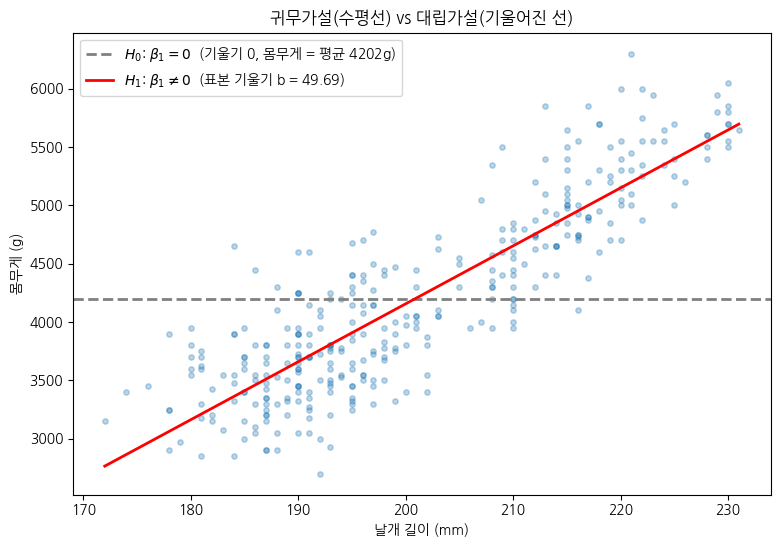

In [22]:
# 문제 4 · Q1
# H₀ (귀무가설): β₁ = 0  -> 날개 길이는 몸무게와 선형 관계가 없다 (기울기 = 0)
# H₁ (대립가설): β₁ ≠ 0  -> 날개 길이는 몸무게와 선형 관계가 있다 (기울기 ≠ 0)

import os, platform, urllib.request
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.formula.api as smf

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

# 문제 3 Q1 (선행 단계)
penguins = sns.load_dataset('penguins')
penguins_cleaned = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])
model = smf.ols('body_mass_g ~ flipper_length_mm', data=penguins_cleaned).fit()

# 문제 4 데이터 준비
print("분석 대상 데이터:", len(penguins_cleaned), "행 (문제 3과 동일)")
print("설명변수: flipper_length_mm  /  반응변수: body_mass_g\n")

# 문제 4 · Q1
print("# 문제 4 · Q1")
print("# 모형: 몸무게 = β₀ + β₁ × 날개길이 + ε")
print("# H₀ (귀무가설): β₁ = 0  -> 날개 길이는 몸무게와 선형 관계가 없다 (기울기 = 0)")
print("# H₁ (대립가설): β₁ ≠ 0  -> 날개 길이는 몸무게와 선형 관계가 있다 (기울기 ≠ 0)")
print("# -> 양측검정: 기울기가 양수든 음수든 0이 아니기만 하면 H₁")

d = penguins_cleaned
x, y = d['flipper_length_mm'], d['body_mass_g']
a, b = model.params
xs = x.sort_values()
plt.figure(figsize=(9, 6))
plt.scatter(x, y, alpha=0.3, s=15)
plt.axhline(y.mean(), color='gray', ls='--', lw=2,
            label=r'$H_0$: $\beta_1 = 0$' + f'  (기울기 0, 몸무게 = 평균 {y.mean():.0f}g)')
plt.plot(xs, a + b * xs, color='red', lw=2,
         label=r'$H_1$: $\beta_1 \neq 0$' + f'  (표본 기울기 b = {b:.2f})')
plt.title('귀무가설(수평선) vs 대립가설(기울어진 선)')
plt.xlabel('날개 길이 (mm)'); plt.ylabel('몸무게 (g)')
plt.legend(loc='upper left'); plt.show()

### Q2 · 기울기의 p-값을 찾아 봅시다

- `flipper_length_mm` 행에서 `P>|t|` 열의 값을 찾아 출력하세요.

- `💡 힌트` 결과표에서 눈으로 찾아도 되고, 모델 객체의 `.pvalues` 속성을 써도 됩니다.

[방법 1] 결과표의 계수 부분
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept         -5780.8314    305.815    -18.903      0.000   -6382.358   -5179.305
flipper_length_mm    49.6856      1.518     32.722      0.000      46.699      52.672
-> flipper_length_mm 행의 P>|t| 열: 0.000 (소수 셋째 자리까지만 표시)

[방법 2] model.pvalues
Intercept             5.587301e-55
flipper_length_mm    4.370681e-107
dtype: float64

-> 기울기의 p-값 = 4.37e-107

[계산 과정] t = b / SE(b),  p = 2 × P(T > |t|)
   t = 49.6856 / 1.5184 = 32.72  (자유도 340)
   p = 2 × P(T_340 > 32.72) = 4.37e-107

-> p = 4.37e-107 < 0.05 이므로 H₀(β₁ = 0) 기각
-> 날개 길이와 몸무게 사이에 통계적으로 유의한 선형 관계가 있다.


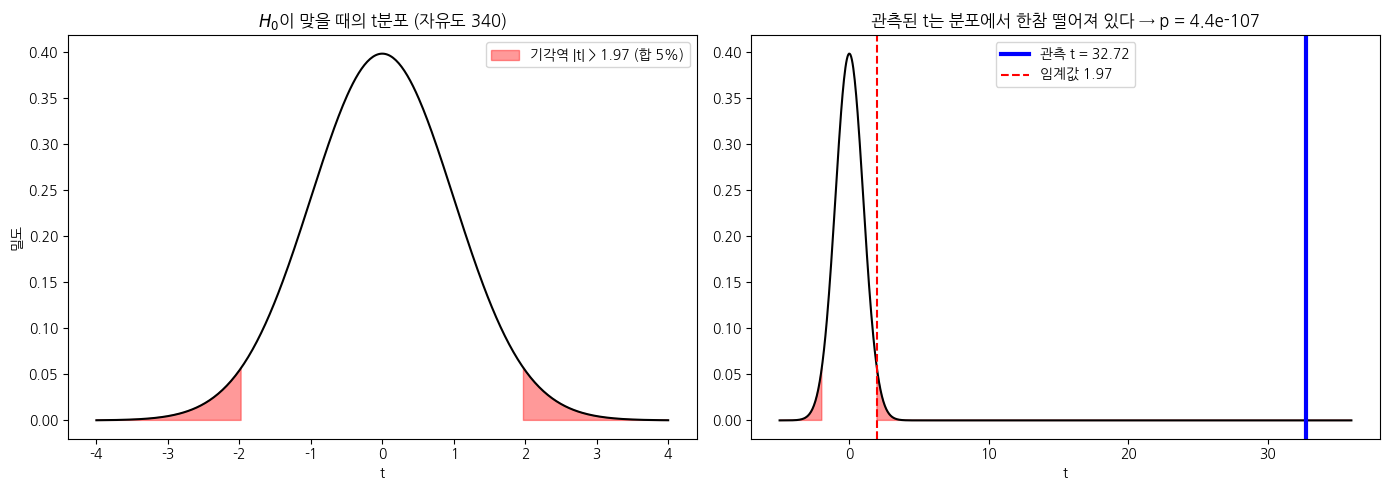

In [23]:
import os, platform, urllib.request
import numpy as np, seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.formula.api as smf
from scipy import stats

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

penguins = sns.load_dataset('penguins')
penguins_cleaned = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])
model = smf.ols('body_mass_g ~ flipper_length_mm', data=penguins_cleaned).fit()
X = 'flipper_length_mm'

# 방법 1: 결과표에서 눈으로 찾기 (계수 표만 출력)
print("[방법 1] 결과표의 계수 부분")
print(model.summary().tables[1])
print(f"-> {X} 행의 P>|t| 열: 0.000 (소수 셋째 자리까지만 표시)\n")

# 방법 2: .pvalues 속성
p_slope = model.pvalues[X]
print("[방법 2] model.pvalues")
print(model.pvalues)
print(f"\n-> 기울기의 p-값 = {p_slope:.2e}")

# p-값이 나온 과정
b, se = model.params[X], model.bse[X]
t, df = model.tvalues[X], model.df_resid
print("\n[계산 과정] t = b / SE(b),  p = 2 × P(T > |t|)")
print(f"   t = {b:.4f} / {se:.4f} = {t:.2f}  (자유도 {df:.0f})")
print(f"   p = 2 × P(T_{df:.0f} > {t:.2f}) = {2 * stats.t.sf(abs(t), df):.2e}")
print(f"\n-> p = {p_slope:.2e} < 0.05 이므로 H₀(β₁ = 0) 기각")
print("-> 날개 길이와 몸무게 사이에 통계적으로 유의한 선형 관계가 있다.")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
tt = np.linspace(-4, 4, 400)
tc = stats.t.ppf(0.975, df)
ax[0].plot(tt, stats.t.pdf(tt, df), 'k-')
ax[0].fill_between(tt, stats.t.pdf(tt, df), where=abs(tt) >= tc, color='red', alpha=0.4,
                   label=f'기각역 |t| > {tc:.2f} (합 5%)')
ax[0].set_title(r'$H_0$이 맞을 때의 t분포 (자유도 340)')
ax[0].set_xlabel('t'); ax[0].set_ylabel('밀도'); ax[0].legend()
tt2 = np.linspace(-5, 36, 800)
ax[1].plot(tt2, stats.t.pdf(tt2, df), 'k-')
ax[1].fill_between(tt2, stats.t.pdf(tt2, df), where=abs(tt2) >= tc, color='red', alpha=0.4)
ax[1].axvline(t, color='blue', lw=3, label=f'관측 t = {t:.2f}')
ax[1].axvline(tc, color='red', ls='--', label=f'임계값 {tc:.2f}')
ax[1].set_title(f'관측된 t는 분포에서 한참 떨어져 있다 → p = {p_slope:.1e}')
ax[1].set_xlabel('t'); ax[1].legend()
plt.tight_layout(); plt.show()

### Q3 · 유의수준 0.05로 결론을 내려 봅시다

- p-값과 유의수준 `alpha = 0.05`를 비교해, **판정 결과를 문장으로 출력하는 코드**를 작성하세요.

- 숫자만 찍지 말고 "기각한다 / 기각하지 못한다"까지 출력되도록 만드세요.

Q3 · 유의수준 0.05로 결론 내리기

기울기의 p-값 = 4.37e-107
유의수준 alpha = 0.05

판정: p-값(4.37e-107) < 유의수준(0.05)
-> 귀무가설 H₀(β₁ = 0)을 기각한다.
-> 날개 길이는 몸무게와 통계적으로 유의한 선형 관계가 있다.


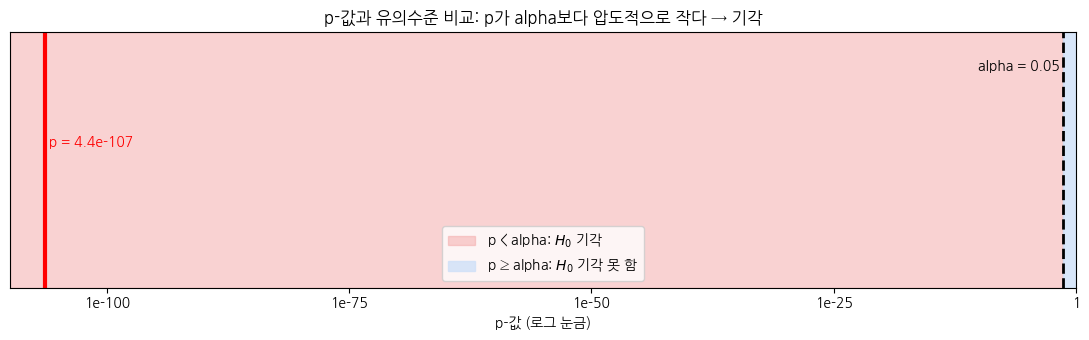

In [24]:
import os, platform, urllib.request
import numpy as np, seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.formula.api as smf

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

penguins = sns.load_dataset('penguins')
penguins_cleaned = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])
model = smf.ols('body_mass_g ~ flipper_length_mm', data=penguins_cleaned).fit()

# Q3 · 유의수준 0.05로 결론 내리기
alpha = 0.05
p_slope = model.pvalues['flipper_length_mm']

print("Q3 · 유의수준 0.05로 결론 내리기\n")
print(f"기울기의 p-값 = {p_slope:.2e}")
print(f"유의수준 alpha = {alpha}\n")

if p_slope < alpha:
    print(f"판정: p-값({p_slope:.2e}) < 유의수준({alpha})")
    print("-> 귀무가설 H₀(β₁ = 0)을 기각한다.")
    print("-> 날개 길이는 몸무게와 통계적으로 유의한 선형 관계가 있다.")
else:
    print(f"판정: p-값({p_slope:.4f}) ≥ 유의수준({alpha})")
    print("-> 귀무가설 H₀(β₁ = 0)을 기각하지 못한다.")
    print("-> 날개 길이와 몸무게의 선형 관계가 있다고 말할 근거가 부족하다.")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.set_xscale('log'); ax.set_xlim(1e-110, 1)
ax.axvspan(1e-110, alpha, color='#f4a6a6', alpha=0.5, label=r'p < alpha: $H_0$ 기각')
ax.axvspan(alpha, 1, color='#cfe0f8', alpha=0.8, label=r'p ≥ alpha: $H_0$ 기각 못 함')
ax.axvline(alpha, color='black', ls='--', lw=2)
ax.text(alpha, 0.85, f'alpha = {alpha} ', ha='right', transform=ax.get_xaxis_transform())
ax.axvline(p_slope, color='red', lw=3)
ax.text(p_slope, 0.55, f' p = {p_slope:.1e}', color='red', transform=ax.get_xaxis_transform())
ticks = [1e-100, 1e-75, 1e-50, 1e-25, 1]
ax.set_xticks(ticks); ax.set_xticklabels(['1e-100', '1e-75', '1e-50', '1e-25', '1'])
ax.minorticks_off()
ax.set_yticks([]); ax.set_xlabel('p-값 (로그 눈금)')
ax.set_title('p-값과 유의수준 비교: p가 alpha보다 압도적으로 작다 → 기각')
ax.legend(loc='lower center'); plt.tight_layout(); plt.show()

### Q4 · 상관계수의 검정과 같은 검정인지 확인해 봅시다

- 강의에서 배운 공식으로 t-통계량을 **직접 계산**하세요.

  `t = r × √(n − 2) / √(1 − r²)`

- 이 값을 `model.tvalues['flipper_length_mm']`와 **나란히 출력**해 비교하세요.

- `💡 힌트` `n`은 표본 크기(`len(penguins_cleaned)`), `r`은 문제 2 Q2에서 구한 값입니다.

Q4 · 상관계수 검정 = 기울기 검정인지 확인

공식: t = r × √(n − 2) / √(1 − r²)
대입: t = 0.8712 × √(342 − 2) / √(1 − 0.8712²)
        = 0.8712 × 18.4391 / 0.4909
        = 32.7222

[t-통계량 비교]
  상관계수 공식 (직접 계산) : 32.7222
  model.tvalues             : 32.7222
  기울기 / 표준오차 (b/SE)  : 32.7222

-> 일치하는가? True

p-값 비교: 피어슨 검정 4.3707e-107  /  기울기 검정 4.3707e-107
-> t와 p가 모두 같다: 단순회귀에서 '기울기 = 0' 검정과 '상관계수 = 0' 검정은 같은 검정이다.


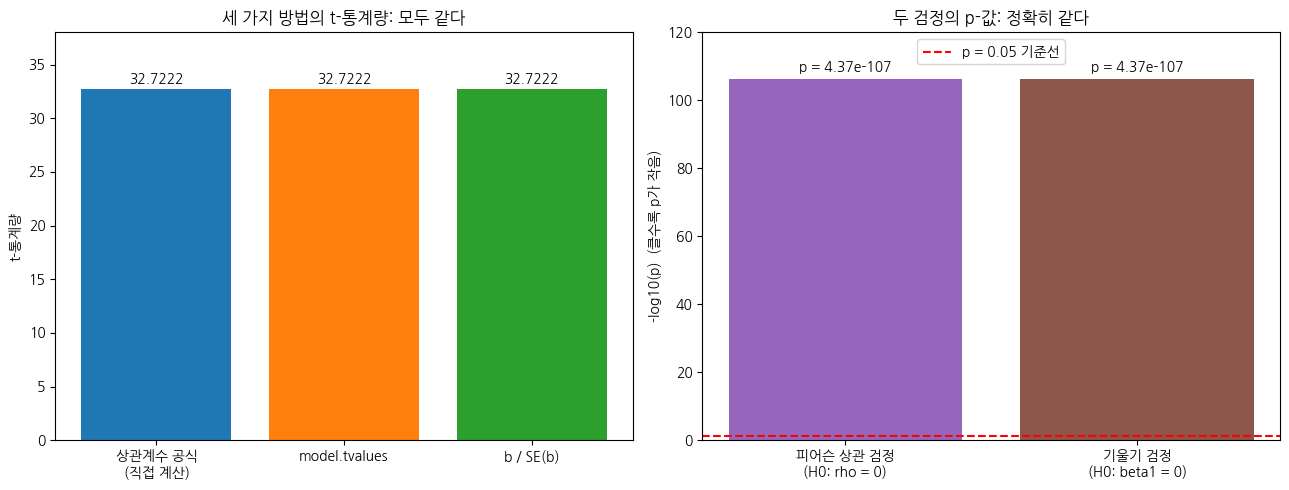

In [25]:
import os, platform, urllib.request
import numpy as np, seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.formula.api as smf
from scipy import stats

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

penguins = sns.load_dataset('penguins')
penguins_cleaned = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])
model = smf.ols('body_mass_g ~ flipper_length_mm', data=penguins_cleaned).fit()
X = 'flipper_length_mm'

# 문제 2 Q2의 r
r, p_value = stats.pearsonr(penguins_cleaned[X], penguins_cleaned['body_mass_g'])
n = len(penguins_cleaned)

# Q4 · 공식으로 t 직접 계산
t_manual = r * np.sqrt(n - 2) / np.sqrt(1 - r**2)
t_model = model.tvalues[X]
t_bse = model.params[X] / model.bse[X]

print("Q4 · 상관계수 검정 = 기울기 검정인지 확인\n")
print("공식: t = r × √(n − 2) / √(1 − r²)")
print(f"대입: t = {r:.4f} × √({n} − 2) / √(1 − {r:.4f}²)")
print(f"        = {r:.4f} × {np.sqrt(n-2):.4f} / {np.sqrt(1-r**2):.4f}")
print(f"        = {t_manual:.4f}\n")

print("[t-통계량 비교]")
print(f"  상관계수 공식 (직접 계산) : {t_manual:.4f}")
print(f"  model.tvalues             : {t_model:.4f}")
print(f"  기울기 / 표준오차 (b/SE)  : {t_bse:.4f}")
print(f"\n-> 일치하는가? {np.isclose(t_manual, t_model)}")
print(f"\np-값 비교: 피어슨 검정 {p_value:.4e}  /  기울기 검정 {model.pvalues[X]:.4e}")
print("-> t와 p가 모두 같다: 단순회귀에서 '기울기 = 0' 검정과 '상관계수 = 0' 검정은 같은 검정이다.")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
labels = ['상관계수 공식\n(직접 계산)', 'model.tvalues', 'b / SE(b)']
vals = [t_manual, t_model, t_bse]
ax[0].bar(labels, vals, color=['#1f77b4', '#ff7f0e', '#2ca02c'])
for i, v in enumerate(vals): ax[0].text(i, v + 0.5, f'{v:.4f}', ha='center')
ax[0].set_ylim(0, 38); ax[0].set_ylabel('t-통계량')
ax[0].set_title('세 가지 방법의 t-통계량: 모두 같다')
lp = [-np.log10(p_value), -np.log10(model.pvalues[X])]
ax[1].bar(['피어슨 상관 검정\n(H0: rho = 0)', '기울기 검정\n(H0: beta1 = 0)'], lp,
          color=['#9467bd', '#8c564b'])
for i, v in enumerate([p_value, model.pvalues[X]]):
    ax[1].text(i, lp[i] + 2, f'p = {v:.2e}', ha='center')
ax[1].axhline(-np.log10(0.05), color='red', ls='--', label='p = 0.05 기준선')
ax[1].set_ylim(0, 120); ax[1].set_ylabel('-log10(p)  (클수록 p가 작음)')
ax[1].set_title('두 검정의 p-값: 정확히 같다'); ax[1].legend()
plt.tight_layout(); plt.show()

### Q5 · p-값이 크게 나오는 사례를 만나 봅시다

- **Adelie 종 수컷만** 골라, `bill_length_mm`으로 `body_mass_g`를 설명하는 회귀를 적합하세요.

- 기울기의 p-값을 유의수준 0.05와 비교하고, 표본 크기(n)와 `R²`도 함께 출력하세요.

- `💡 힌트` 먼저 필요한 열의 결측치를 제거한 뒤 조건으로 걸러 냅니다.
  `df[(df['species'] == 'Adelie') & (df['sex'] == 'Male')]`

                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept       2687.8780    713.222      3.769      0.000    1265.755    4110.001
bill_length_mm    33.5628     17.631      1.904      0.061      -1.592      68.717

Q5 · Adelie 수컷: 부리 길이 → 몸무게
  표본 크기 n = 73
  기울기 b    = 33.56 g/mm
  p-값        = 0.0610
  R²          = 0.0486  (몸무게 변동의 4.9%만 설명)
  유의수준    = 0.05

판정: p(0.0610) ≥ 0.05 -> 귀무가설(β₁ = 0)을 기각하지 못한다.
-> Adelie 수컷 안에서는 부리 길이와 몸무게의 선형 관계를 확인할 근거가 부족하다.

[문제 3과 비교]
  문제 3 (전체, 날개→몸무게): n = 342, R² = 0.759, p = 4.37e-107 -> 기각
  Q5 (Adelie 수컷, 부리→몸무게): n = 73, R² = 0.049, p = 0.061
-> 표본이 작고(n↓), 관계가 약하면(R²↓) p-값이 커진다.


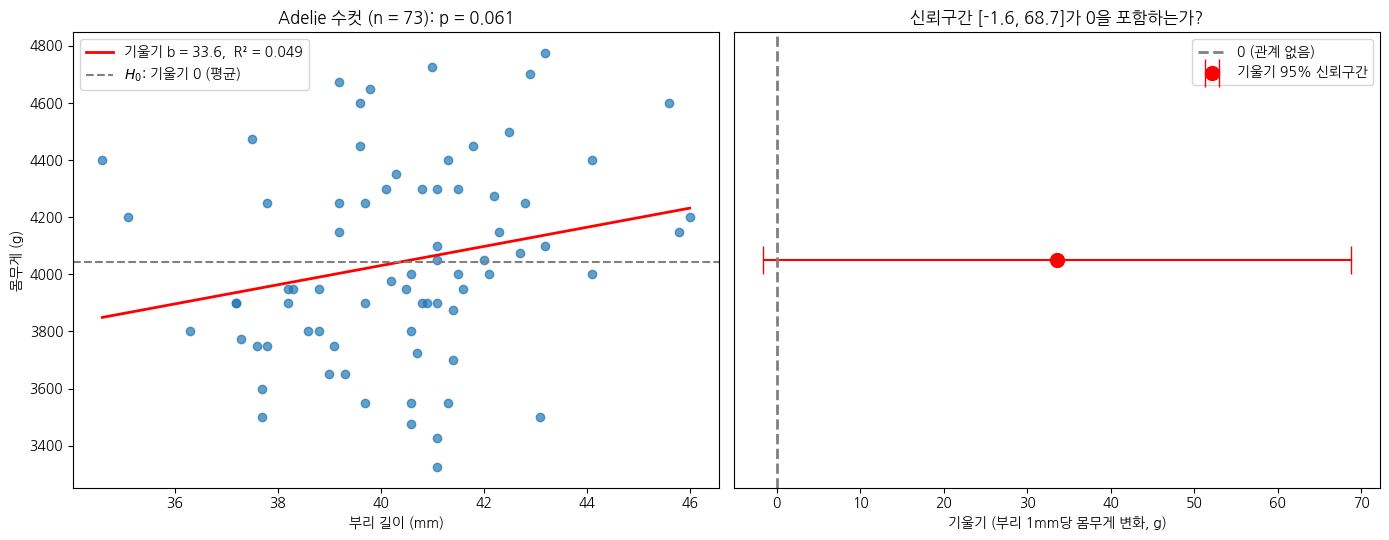

In [26]:
import os, platform, urllib.request
import numpy as np, seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.formula.api as smf

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

penguins = sns.load_dataset('penguins')

# 1) 결측치 제거 -> 2) Adelie 수컷만 선택
df = penguins.dropna(subset=['bill_length_mm', 'body_mass_g', 'sex'])
adelie_m = df[(df['species'] == 'Adelie') & (df['sex'] == 'Male')]

# 3) 회귀 적합
model_am = smf.ols('body_mass_g ~ bill_length_mm', data=adelie_m).fit()
print(model_am.summary().tables[1])

alpha = 0.05
b = model_am.params['bill_length_mm']
p_am = model_am.pvalues['bill_length_mm']
n, r2 = int(model_am.nobs), model_am.rsquared

print("\nQ5 · Adelie 수컷: 부리 길이 → 몸무게")
print(f"  표본 크기 n = {n}")
print(f"  기울기 b    = {b:.2f} g/mm")
print(f"  p-값        = {p_am:.4f}")
print(f"  R²          = {r2:.4f}  (몸무게 변동의 {r2*100:.1f}%만 설명)")
print(f"  유의수준    = {alpha}\n")
if p_am < alpha:
    print(f"판정: p({p_am:.4f}) < {alpha} -> 귀무가설(β₁ = 0)을 기각한다.")
else:
    print(f"판정: p({p_am:.4f}) ≥ {alpha} -> 귀무가설(β₁ = 0)을 기각하지 못한다.")
    print("-> Adelie 수컷 안에서는 부리 길이와 몸무게의 선형 관계를 확인할 근거가 부족하다.")
print("\n[문제 3과 비교]")
print("  문제 3 (전체, 날개→몸무게): n = 342, R² = 0.759, p = 4.37e-107 -> 기각")
print(f"  Q5 (Adelie 수컷, 부리→몸무게): n = {n}, R² = {r2:.3f}, p = {p_am:.3f}")
print("-> 표본이 작고(n↓), 관계가 약하면(R²↓) p-값이 커진다.")

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
x, y = adelie_m['bill_length_mm'], adelie_m['body_mass_g']
ax[0].scatter(x, y, alpha=0.7, color='#1f77b4')
xs = np.linspace(x.min(), x.max(), 100)
ax[0].plot(xs, model_am.params['Intercept'] + b * xs, 'r-', lw=2,
           label=f'기울기 b = {b:.1f},  R² = {r2:.3f}')
ax[0].axhline(y.mean(), color='gray', ls='--', label=r'$H_0$: 기울기 0 (평균)')
ax[0].set_title(f'Adelie 수컷 (n = {n}): p = {p_am:.3f}')
ax[0].set_xlabel('부리 길이 (mm)'); ax[0].set_ylabel('몸무게 (g)'); ax[0].legend()
ci = model_am.conf_int().loc['bill_length_mm']
ax[1].errorbar(b, 0, xerr=[[b - ci[0]], [ci[1] - b]], fmt='o', color='red',
               capsize=10, ms=10, label='기울기 95% 신뢰구간')
ax[1].axvline(0, color='gray', ls='--', lw=2, label='0 (관계 없음)')
ax[1].set_yticks([]); ax[1].legend()
ax[1].set_title(f'신뢰구간 [{ci[0]:.1f}, {ci[1]:.1f}]가 0을 포함하는가?')
ax[1].set_xlabel('기울기 (부리 1mm당 몸무게 변화, g)')
plt.tight_layout(); plt.show()

### 💬 정리 · 결과를 말로 설명해 보기

- p-값이 작다는 것은 정확히 무엇이 작다는 뜻인가요? "귀무가설이 참일 확률"이라고 말해도 될까요?

- Q4에서 두 t값이 일치했습니다. 이것은 상관계수의 검정과 회귀계수의 검정이 **어떤 관계**임을 뜻하나요?

- Q5의 결과는 Q2와 어떻게 달랐나요? 같은 `penguins` 데이터인데 결론이 갈린 이유를 **표본 크기**와 **관계의 강도(R²)** 두 측면에서 설명해 보세요.

- Q5처럼 p-값이 0.05보다 조금 큰 경우, "두 변수는 관계가 없음이 증명되었다"고 말할 수 있을까요? 어떻게 말하는 것이 정확할까요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- p-값은 "H₀가 참이라고 **가정했을 때** 이런 결과가 나올 확률"입니다. 가정과 결론의 방향을 뒤집지 않도록 문장을 조심해서 써 보세요.

- Q4의 일치는 우연이 아닙니다. 단순회귀에서는 "두 변수가 무관하다"는 하나의 가설을 두 가지 방식으로 적었을 뿐입니다 — 그래서 t도 p도 같습니다.

- 기각 실패는 **"관계가 없다"가 아니라 "관계가 있다는 증거가 부족하다"**입니다. Q5의 n과 R²를 보면 왜 증거가 부족했는지 짐작할 수 있습니다.

</details>

1. p-값이 작다는 것은 무엇이 작다는 뜻인가?
   'H₀가 참이라고 가정했을 때, 지금 같은(또는 더 극단적인) 결과가 나올 확률'이 작다는 뜻.
   -> 'H₀가 참일 확률'이 아니다. p-값은 H₀를 참으로 놓고 계산한 값이라
      H₀ 자체가 맞을 확률을 알려줄 수 없다.
   예) Q2의 p = 4.4e-107: 기울기가 진짜 0이라면
       이렇게 큰 기울기가 우연히 나올 확률이 거의 0이라는 뜻.

2. Q4에서 두 t값이 일치한 의미
   상관계수 공식 t = 32.7222,  회귀 기울기 t = 32.7222
   -> 단순회귀에서 'ρ = 0' 검정과 'β₁ = 0' 검정은 완전히 같은 검정이다.
   -> 기울기 b = r × (sy/sx)라서, 단위만 다를 뿐 같은 정보를 검정한다.

3. Q5가 Q2와 달랐던 이유
   Q2 (전체, 날개→몸무게)   : n = 342,  R² = 0.759,  p = 4.4e-107 -> 기각
   Q5 (Adelie 수컷, 부리→몸무게): n = 73,   R² = 0.049,  p = 0.061 -> 기각 못 함
   ① 표본 크기: 342 -> 73으로 줄어 표준오차가 커지고, 같은 관계도 판단하기 어려워졌다.
   ② 관계의 강도: R²가 0.76 -> 0.05로 크게 약해졌다.
      설명변수가 날개에서 부리로 바뀌었고, 한 종·한 성별 안으로 좁히면서
      종·성별 간 몸집 차이가 만들던 관계도 사라졌다.
   -> t = r√(n−2)/√(1−r²) 에서 n과 r이 둘 다 작아져 t가 작아지고 p가 커졌다.

4. p = 0.061이면 '관계가 없음이 증명되었다'고 말할 수 있나? -> 없다.
   p ≥ 0.05는 'H₀를 기각할 증거가 부족하다'는 뜻이지 'H₀가 참'이라는 뜻이 아니다.
   기울기 95% 신뢰구간 [-1.6, 68.7]: 0도 가능하지만 최대 69g/mm 효과도 가능하다.
   정확한 표현: '유의수준 0.05에서 Adelie 수컷의 부리 길

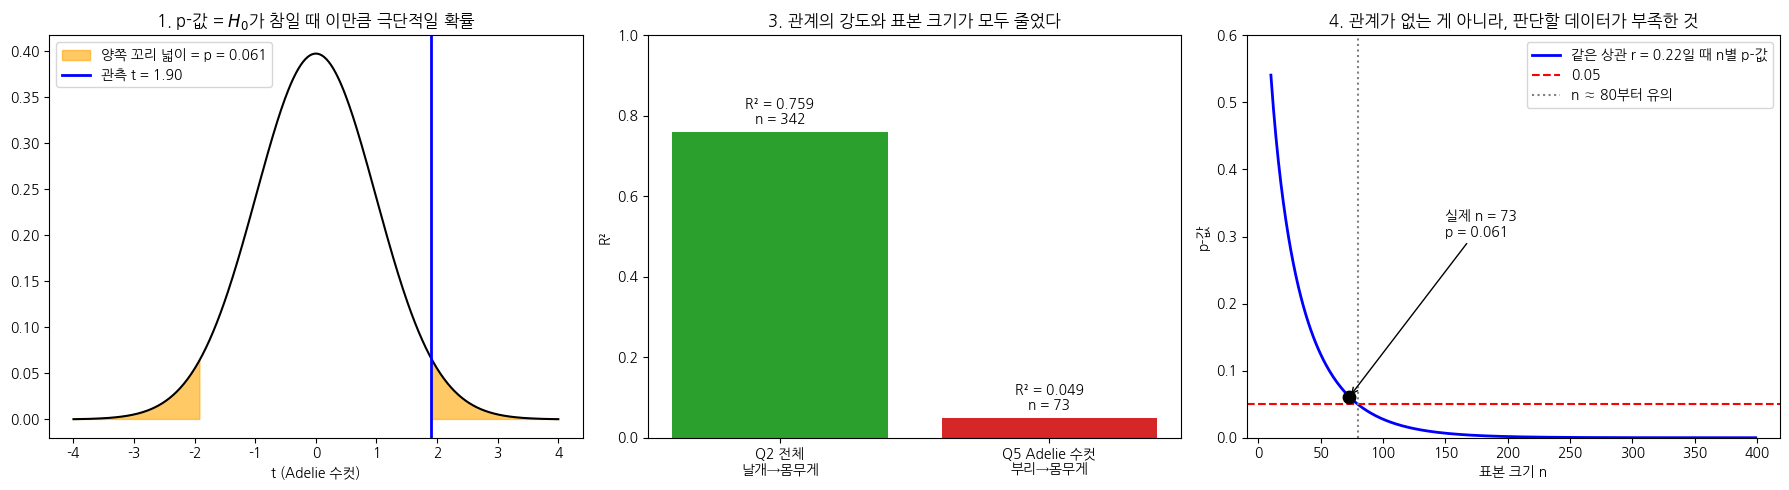

In [35]:
import os, platform, urllib.request
import numpy as np, seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.formula.api as smf
from scipy import stats

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

penguins = sns.load_dataset('penguins')
pc = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])
model = smf.ols('body_mass_g ~ flipper_length_mm', data=pc).fit()
r, p_r = stats.pearsonr(pc['flipper_length_mm'], pc['body_mass_g'])
n = len(pc)
t_r = r * np.sqrt(n - 2) / np.sqrt(1 - r**2)

df = penguins.dropna(subset=['bill_length_mm', 'body_mass_g', 'sex'])
am = df[(df['species'] == 'Adelie') & (df['sex'] == 'Male')]
model_am = smf.ols('body_mass_g ~ bill_length_mm', data=am).fit()
n5, r2_5, p5 = int(model_am.nobs), model_am.rsquared, model_am.pvalues['bill_length_mm']
t5, df5 = model_am.tvalues['bill_length_mm'], model_am.df_resid
r5 = np.sqrt(r2_5)

print("1. p-값이 작다는 것은 무엇이 작다는 뜻인가?")
print("   'H₀가 참이라고 가정했을 때, 지금 같은(또는 더 극단적인) 결과가 나올 확률'이 작다는 뜻.")
print("   -> 'H₀가 참일 확률'이 아니다. p-값은 H₀를 참으로 놓고 계산한 값이라")
print("      H₀ 자체가 맞을 확률을 알려줄 수 없다.")
print(f"   예) Q2의 p = {model.pvalues['flipper_length_mm']:.1e}: 기울기가 진짜 0이라면")
print("       이렇게 큰 기울기가 우연히 나올 확률이 거의 0이라는 뜻.\n")

print("2. Q4에서 두 t값이 일치한 의미")
print(f"   상관계수 공식 t = {t_r:.4f},  회귀 기울기 t = {model.tvalues['flipper_length_mm']:.4f}")
print("   -> 단순회귀에서 'ρ = 0' 검정과 'β₁ = 0' 검정은 완전히 같은 검정이다.")
print("   -> 기울기 b = r × (sy/sx)라서, 단위만 다를 뿐 같은 정보를 검정한다.\n")

print("3. Q5가 Q2와 달랐던 이유")
print(f"   Q2 (전체, 날개→몸무게)   : n = {n},  R² = {model.rsquared:.3f},  p = {model.pvalues['flipper_length_mm']:.1e} -> 기각")
print(f"   Q5 (Adelie 수컷, 부리→몸무게): n = {n5},   R² = {r2_5:.3f},  p = {p5:.3f} -> 기각 못 함")
print(f"   ① 표본 크기: {n} -> {n5}으로 줄어 표준오차가 커지고, 같은 관계도 판단하기 어려워졌다.")
print(f"   ② 관계의 강도: R²가 {model.rsquared:.2f} -> {r2_5:.2f}로 크게 약해졌다.")
print("      설명변수가 날개에서 부리로 바뀌었고, 한 종·한 성별 안으로 좁히면서")
print("      종·성별 간 몸집 차이가 만들던 관계도 사라졌다.")
print("   -> t = r√(n−2)/√(1−r²) 에서 n과 r이 둘 다 작아져 t가 작아지고 p가 커졌다.\n")

print("4. p = 0.061이면 '관계가 없음이 증명되었다'고 말할 수 있나? -> 없다.")
print("   p ≥ 0.05는 'H₀를 기각할 증거가 부족하다'는 뜻이지 'H₀가 참'이라는 뜻이 아니다.")
ci = model_am.conf_int().loc['bill_length_mm']
print(f"   기울기 95% 신뢰구간 [{ci[0]:.1f}, {ci[1]:.1f}]: 0도 가능하지만 최대 {ci[1]:.0f}g/mm 효과도 가능하다.")
print("   정확한 표현: '유의수준 0.05에서 Adelie 수컷의 부리 길이와 몸무게 사이에")
print("              통계적으로 유의한 선형 관계를 확인하지 못했다.'")

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
tt = np.linspace(-4, 4, 400)
ax[0].plot(tt, stats.t.pdf(tt, df5), 'k-')
ax[0].fill_between(tt, stats.t.pdf(tt, df5), where=abs(tt) >= abs(t5), color='orange', alpha=0.6,
                   label=f'양쪽 꼬리 넓이 = p = {p5:.3f}')
ax[0].axvline(t5, color='blue', lw=2, label=f'관측 t = {t5:.2f}')
ax[0].set_title(r'1. p-값 = $H_0$가 참일 때 이만큼 극단적일 확률')
ax[0].set_xlabel('t (Adelie 수컷)'); ax[0].legend(loc='upper left')

lab = ['Q2 전체\n날개→몸무게', 'Q5 Adelie 수컷\n부리→몸무게']
ax[1].bar(lab, [model.rsquared, r2_5], color=['#2ca02c', '#d62728'])
for i, (v, nn) in enumerate([(model.rsquared, n), (r2_5, n5)]):
    ax[1].text(i, v + 0.02, f'R² = {v:.3f}\nn = {nn}', ha='center')
ax[1].set_ylim(0, 1); ax[1].set_ylabel('R²')
ax[1].set_title('3. 관계의 강도와 표본 크기가 모두 줄었다')

nn = np.arange(10, 400)
pp = [2 * stats.t.sf(r5 * np.sqrt(k - 2) / np.sqrt(1 - r5**2), k - 2) for k in nn]
ax[2].plot(nn, pp, 'b-', lw=2, label=f'같은 상관 r = {r5:.2f}일 때 n별 p-값')
ax[2].axhline(0.05, color='red', ls='--', label='0.05')
ax[2].scatter([n5], [p5], color='black', s=80, zorder=5)
ax[2].annotate(f'실제 n = {n5}\np = {p5:.3f}', (n5, p5), xytext=(150, 0.3),
               arrowprops=dict(arrowstyle='->'))
n_sig = nn[np.argmax(np.array(pp) < 0.05)]
ax[2].axvline(n_sig, color='gray', ls=':', label=f'n ≈ {n_sig}부터 유의')
ax[2].set_xlabel('표본 크기 n'); ax[2].set_ylabel('p-값'); ax[2].set_ylim(0, 0.6)
ax[2].set_title('4. 관계가 없는 게 아니라, 판단할 데이터가 부족한 것')
ax[2].legend()
plt.tight_layout(); plt.show()

## 문제 5 · 미니 프로젝트 — 이 회귀모형, 믿고 보고해도 될까?

`난이도 상` · `예상 35분`

**📖 상황**

- 계수가 유의하다고 해서 분석이 끝난 것은 아닙니다. 보고서를 쓰기 전에 두 가지를 더 확인합니다.

- **① 얼마나 설명하는가 — 결정계수(R²)**
  반응변수 전체 변동 중 이 모델이 설명한 비율입니다.

- **② 전제가 지켜졌는가 — 잔차(Residual) 진단**
  잔차는 `실제값 − 예측값`입니다. 좋은 모델이라면 잔차가 **패턴 없이 0 주위에 고르게** 흩어져야 합니다.
  깔때기(부채꼴) 모양이면 **등분산성**이 깨졌다는 신호이고, 이때는 p-값과 신뢰구간을 그대로 믿기 어렵습니다.

**🎯 이 문제로 배우는 것**

- 우리 모형을 진단한 뒤, **일부러 문제가 있는 다른 모형과 나란히 놓고 비교**합니다.
  "통과한 잔차"만 보면 진단을 왜 하는지 알 수 없기 때문입니다.

In [27]:
# 문제 5 · 데이터 준비 — 실행만 하세요
# 문제 3의 Q1을 먼저 완료해야 이 문제를 풀 수 있습니다.

print("분석 대상 데이터:", len(penguins_cleaned), "행")
print("모형: body_mass_g ~ flipper_length_mm")

분석 대상 데이터: 342 행
모형: body_mass_g ~ flipper_length_mm


### Q1 · 결정계수로 설명력을 평가해 봅시다

- 모델의 `R-squared` 값을 출력하세요.

- 그 값이 뜻하는 바를 "몸무게 변동의 몇 %" 형태로 오른쪽 빈칸에 쓰세요.

- `💡 힌트` `model.rsquared`

분석 대상 데이터: 342 행
모형: body_mass_g ~ flipper_length_mm

R-squared = 0.7590
-> 몸무게 변동의 약 75.9%를 날개 길이로 설명할 수 있다.
-> 나머지 24.1%는 이 모델로 설명되지 않는다 (종·성별·개체 차이 등).

[계산 과정] R² = 1 − SSE / SST
   SST (전체 변동)     = 219,307,697
   SSE (잔차 변동)     = 52,854,796
   R² = 1 − 52,854,796 / 219,307,697 = 0.7590


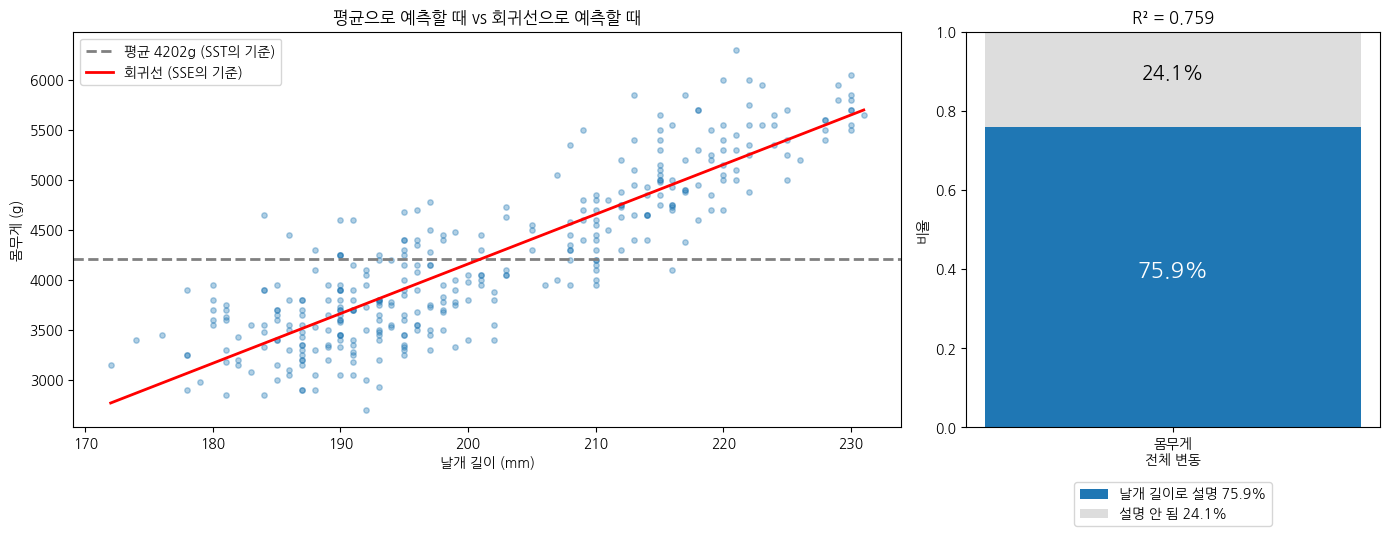

In [28]:
# 문제 5 · Q1
# R² 값: 0.759
# 의미 : 몸무게 변동의 약 75.9%를 날개 길이로 설명할 수 있다.

import os, platform, urllib.request
import numpy as np, seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.formula.api as smf

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

# 문제 3 Q1 (선행 단계)
penguins = sns.load_dataset('penguins')
penguins_cleaned = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])
model = smf.ols('body_mass_g ~ flipper_length_mm', data=penguins_cleaned).fit()

# 문제 5 데이터 준비
print("분석 대상 데이터:", len(penguins_cleaned), "행")
print("모형: body_mass_g ~ flipper_length_mm\n")

# Q1 · 결정계수
r2 = model.rsquared
y = penguins_cleaned['body_mass_g']
SST = ((y - y.mean())**2).sum()
SSE = (model.resid**2).sum()
SSR = SST - SSE

print(f"R-squared = {r2:.4f}")
print(f"-> 몸무게 변동의 약 {r2*100:.1f}%를 날개 길이로 설명할 수 있다.")
print(f"-> 나머지 {100 - r2*100:.1f}%는 이 모델로 설명되지 않는다 (종·성별·개체 차이 등).\n")
print("[계산 과정] R² = 1 − SSE / SST")
print(f"   SST (전체 변동)     = {SST:,.0f}")
print(f"   SSE (잔차 변동)     = {SSE:,.0f}")
print(f"   R² = 1 − {SSE:,.0f} / {SST:,.0f} = {1 - SSE/SST:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [2, 1]})
x = penguins_cleaned['flipper_length_mm']
a, b = model.params
xs = np.sort(x)
ax[0].scatter(x, y, alpha=0.35, s=15)
ax[0].axhline(y.mean(), color='gray', ls='--', lw=2, label=f'평균 {y.mean():.0f}g (SST의 기준)')
ax[0].plot(xs, a + b * xs, 'r-', lw=2, label='회귀선 (SSE의 기준)')
ax[0].set_title('평균으로 예측할 때 vs 회귀선으로 예측할 때')
ax[0].set_xlabel('날개 길이 (mm)'); ax[0].set_ylabel('몸무게 (g)'); ax[0].legend(loc='upper left')
ax[1].bar(['몸무게\n전체 변동'], [r2], color='#1f77b4', label=f'날개 길이로 설명 {r2:.1%}')
ax[1].bar(['몸무게\n전체 변동'], [1 - r2], bottom=[r2], color='#dddddd',
          label=f'설명 안 됨 {1 - r2:.1%}')
ax[1].text(0, r2 / 2, f'{r2:.1%}', ha='center', color='white', fontsize=16)
ax[1].text(0, r2 + (1 - r2) / 2, f'{1 - r2:.1%}', ha='center', fontsize=14)
ax[1].set_ylim(0, 1); ax[1].set_ylabel('비율')
ax[1].set_title(f'R² = {r2:.3f}'); ax[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()

### Q2 · 예측값과 잔차를 계산해 봅시다

- 모델의 **예측값**과 **잔차**를 각각 계산해 변수에 저장하세요.

- 잔차의 개수와 평균을 함께 출력해, 잔차가 0 주위에 모여 있는지 확인하세요.

- `💡 힌트` 예측값은 `.fittedvalues`, 잔차는 `.resid` 속성입니다.

[앞 5마리] 잔차 = 실제 − 예측
   날개길이  실제 y   예측 ŷ  잔차 y−ŷ
0     181.0  3750.0  3212.26    537.74
1     186.0  3800.0  3460.68    339.32
2     195.0  3250.0  3907.85   -657.85
4     193.0  3450.0  3808.48   -358.48
5     190.0  3650.0  3659.43     -9.43 

잔차 개수 = 342
잔차 평균 = 0.000000  (사실상 0)
잔차 표준편차 = 393.70 g
잔차 범위 = -1058.8 ~ 1288.7 g

-> 잔차가 0을 중심으로 위아래로 고르게 흩어져 있다.
-> 절편이 있는 OLS는 잔차의 합(평균)이 항상 0이 되도록 선을 긋는다.


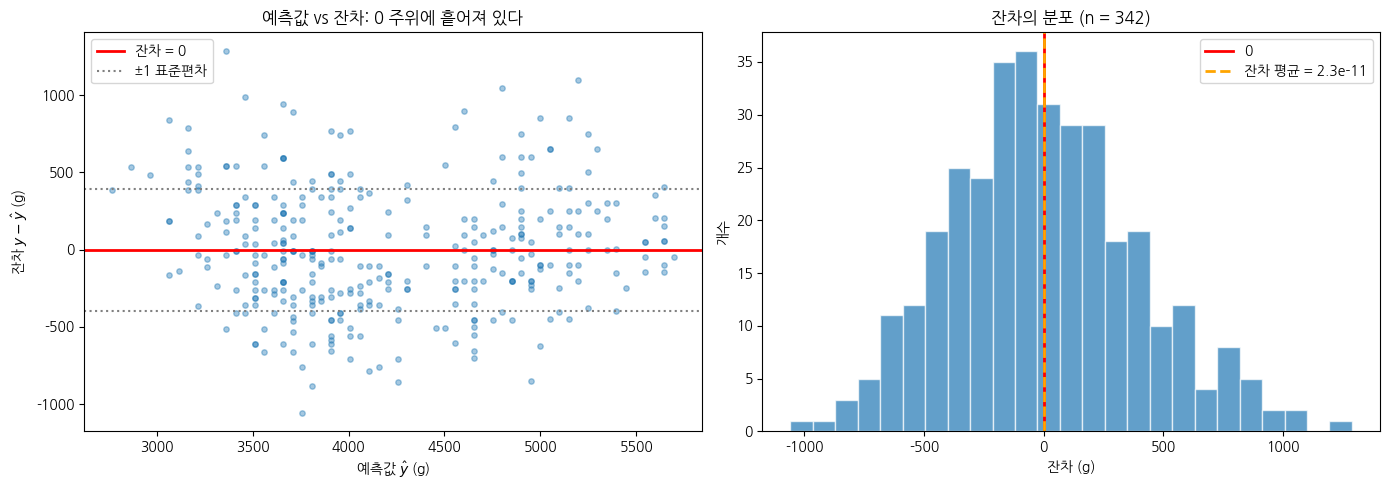

In [29]:
import os, platform, urllib.request
import numpy as np, pandas as pd, seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.formula.api as smf

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

penguins = sns.load_dataset('penguins')
penguins_cleaned = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])
model = smf.ols('body_mass_g ~ flipper_length_mm', data=penguins_cleaned).fit()

# Q2 · 예측값과 잔차 저장
fitted = model.fittedvalues      # 예측값 ŷ
residuals = model.resid          # 잔차 e = y − ŷ

y = penguins_cleaned['body_mass_g']
table = pd.DataFrame({'날개길이': penguins_cleaned['flipper_length_mm'],
                      '실제 y': y, '예측 ŷ': fitted, '잔차 y−ŷ': residuals})
print("[앞 5마리] 잔차 = 실제 − 예측")
print(table.head().round(2), "\n")

print(f"잔차 개수 = {len(residuals)}")
print(f"잔차 평균 = {residuals.mean():.6f}  (사실상 0)")
print(f"잔차 표준편차 = {residuals.std():.2f} g")
print(f"잔차 범위 = {residuals.min():.1f} ~ {residuals.max():.1f} g\n")
print("-> 잔차가 0을 중심으로 위아래로 고르게 흩어져 있다.")
print("-> 절편이 있는 OLS는 잔차의 합(평균)이 항상 0이 되도록 선을 긋는다.")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(fitted, residuals, alpha=0.4, s=15)
ax[0].axhline(0, color='red', lw=2, label='잔차 = 0')
ax[0].axhline(residuals.std(), color='gray', ls=':', label='±1 표준편차')
ax[0].axhline(-residuals.std(), color='gray', ls=':')
ax[0].set_title('예측값 vs 잔차: 0 주위에 흩어져 있다')
ax[0].set_xlabel(r'예측값 $\hat{y}$ (g)'); ax[0].set_ylabel(r'잔차 $y - \hat{y}$ (g)'); ax[0].legend()
ax[1].hist(residuals, bins=25, color='#1f77b4', alpha=0.7, edgecolor='white')
ax[1].axvline(0, color='red', lw=2, label='0')
ax[1].axvline(residuals.mean(), color='orange', ls='--', lw=2,
              label=f'잔차 평균 = {residuals.mean():.1e}')
ax[1].set_title(f'잔차의 분포 (n = {len(residuals)})')
ax[1].set_xlabel('잔차 (g)'); ax[1].set_ylabel('개수'); ax[1].legend()
plt.tight_layout(); plt.show()

### Q3 · 잔차 산점도를 그려 봅시다

- 가로축을 **예측값**, 세로축을 **잔차**로 하는 산점도를 그리세요.

- `y = 0` 기준선을 함께 표시하면 패턴을 보기 쉽습니다.

- `💡 힌트` `plt.scatter()` 와 `plt.axhline(0, color='red', linestyle='--')`

[예측값 구간별 잔차]
  낮은 예측값: 평균    56.9 g,  표준편차  406.6 g
  중간 예측값: 평균  -110.3 g,  표준편차  398.7 g
  높은 예측값: 평균    41.5 g,  표준편차  365.3 g

-> 퍼짐(표준편차)은 구간마다 비슷해 뚜렷한 깔때기 모양은 없다.
-> 다만 중간 구간 평균이 음수라, 추세선이 살짝 U자로 휜다.

[종별 잔차 평균]
species
Adelie        43.5
Chinstrap   -215.7
Gentoo        65.8

-> Chinstrap은 잔차가 대부분 0 아래: 날개 길이에 비해 실제로 더 가볍다.
-> 즉 U자 패턴은 '종'이라는 빠진 변수 때문이며, 종을 모델에 넣으면 개선될 수 있다.


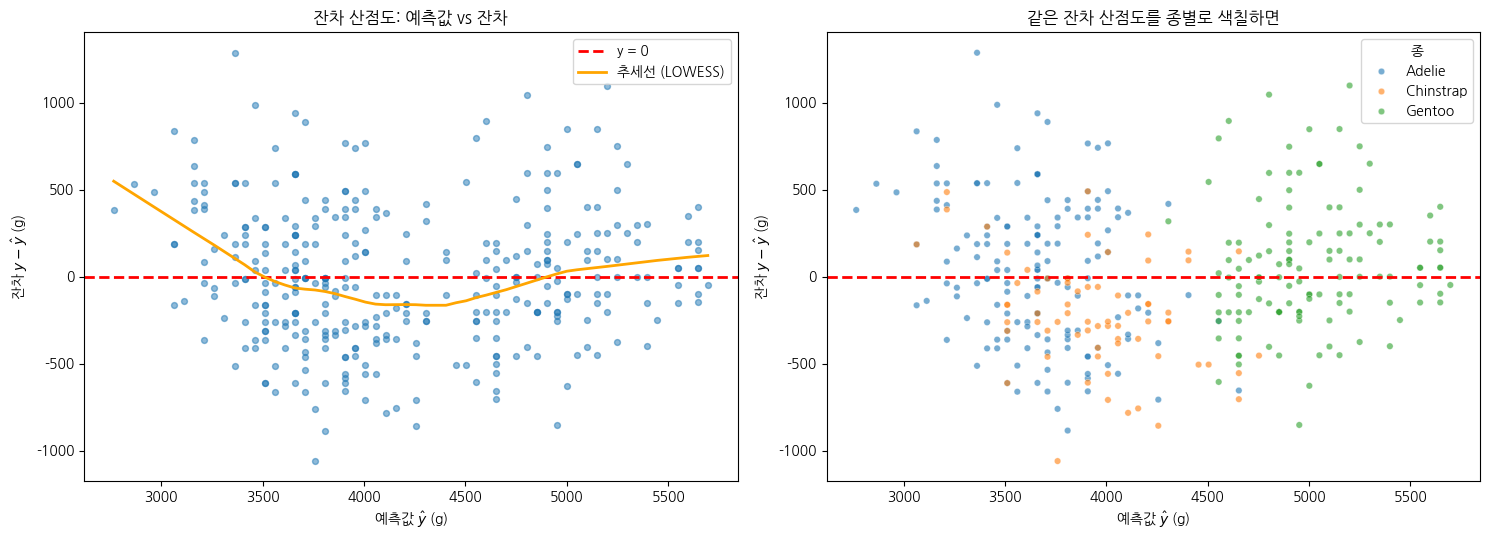

In [30]:
import os, platform, urllib.request
import numpy as np, seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.formula.api as smf
from statsmodels.nonparametric.smoothers_lowess import lowess

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

penguins = sns.load_dataset('penguins')
penguins_cleaned = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])
model = smf.ols('body_mass_g ~ flipper_length_mm', data=penguins_cleaned).fit()
fitted = model.fittedvalues
residuals = model.resid

# 예측값 구간별 잔차의 퍼짐 확인
bins = np.quantile(fitted, [0, 1/3, 2/3, 1])
labels = ['낮은 예측값', '중간 예측값', '높은 예측값']
print("[예측값 구간별 잔차]")
for i, lab in enumerate(labels):
    m = (fitted >= bins[i]) & (fitted <= bins[i + 1])
    print(f"  {lab}: 평균 {residuals[m].mean():7.1f} g,  표준편차 {residuals[m].std():6.1f} g")
print("\n-> 퍼짐(표준편차)은 구간마다 비슷해 뚜렷한 깔때기 모양은 없다.")
print("-> 다만 중간 구간 평균이 음수라, 추세선이 살짝 U자로 휜다.")

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
# 왼쪽: 기본 잔차 산점도
ax[0].scatter(fitted, residuals, alpha=0.5, s=18)
ax[0].axhline(0, color='red', linestyle='--', lw=2, label='y = 0')
sm = lowess(residuals, fitted, frac=0.4)
ax[0].plot(sm[:, 0], sm[:, 1], color='orange', lw=2, label='추세선 (LOWESS)')
ax[0].set_title('잔차 산점도: 예측값 vs 잔차')
ax[0].set_xlabel(r'예측값 $\hat{y}$ (g)'); ax[0].set_ylabel(r'잔차 $y - \hat{y}$ (g)')
ax[0].legend()
# 오른쪽: 종별로 색 구분
sns.scatterplot(x=fitted, y=residuals, hue=penguins_cleaned['species'],
                alpha=0.6, s=22, ax=ax[1])
ax[1].axhline(0, color='red', linestyle='--', lw=2)
ax[1].set_title('같은 잔차 산점도를 종별로 색칠하면')
ax[1].set_xlabel(r'예측값 $\hat{y}$ (g)'); ax[1].set_ylabel(r'잔차 $y - \hat{y}$ (g)')
ax[1].legend(title='종')
plt.tight_layout(); plt.show()

print("\n[종별 잔차 평균]")
print(residuals.groupby(penguins_cleaned['species']).mean().round(1).to_string())
print("\n-> Chinstrap은 잔차가 대부분 0 아래: 날개 길이에 비해 실제로 더 가볍다.")
print("-> 즉 U자 패턴은 '종'이라는 빠진 변수 때문이며, 종을 모델에 넣으면 개선될 수 있다.")

### Q4 · 등분산성을 숫자로 검정해 봅시다

- **브루쉬-페이건 검정**으로 등분산성을 확인하세요.

- H₀는 "등분산이다"입니다. p-값이 0.05보다 작으면 이분산을 의심합니다.

- 판정 결과를 문장으로 함께 출력하세요.

- `💡 힌트` `het_breuschpagan(잔차, model.model.exog)`는
  `(LM통계량, LM p-값, F통계량, F p-값)`을 돌려줍니다.

Q4 · 브루쉬-페이건(Breusch-Pagan) 등분산성 검정
H₀: 등분산이다 (잔차의 퍼짐이 일정하다)
H₁: 이분산이다 (잔차의 퍼짐이 설명변수에 따라 변한다)

LM 통계량 = 2.1579,  LM p-값 = 0.1418
F  통계량 = 2.1589,  F  p-값 = 0.1427

판정: p-값(0.1418) ≥ 0.05 -> H₀를 기각하지 못한다.
-> 등분산 가정을 위반했다고 볼 근거가 없다.

[검정 원리] 잔차²를 설명변수로 회귀한 보조회귀의 R²로 판단
   보조회귀 R² = 0.0063
   LM = n × R² = 342 × 0.0063 = 2.1579
   자유도 1인 카이제곱분포에서 p = 0.1418


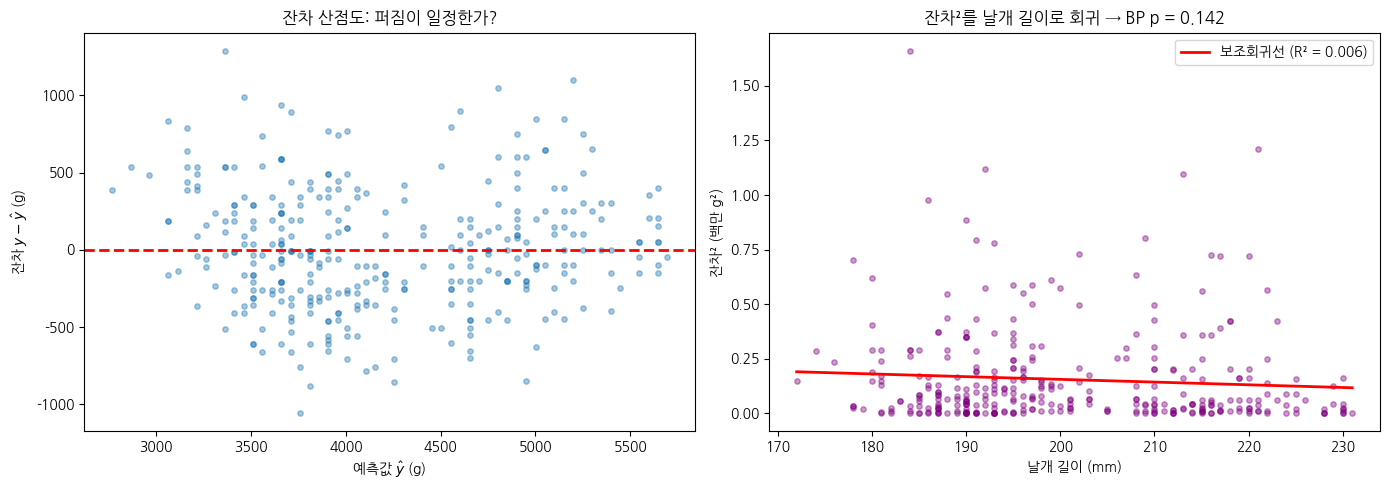

In [31]:
import os, platform, urllib.request
import numpy as np, seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy import stats

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

penguins = sns.load_dataset('penguins')
penguins_cleaned = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])
model = smf.ols('body_mass_g ~ flipper_length_mm', data=penguins_cleaned).fit()
fitted, residuals = model.fittedvalues, model.resid

# Q4 · 브루쉬-페이건 검정
lm, lm_p, f, f_p = het_breuschpagan(residuals, model.model.exog)
alpha = 0.05

print("Q4 · 브루쉬-페이건(Breusch-Pagan) 등분산성 검정")
print("H₀: 등분산이다 (잔차의 퍼짐이 일정하다)")
print("H₁: 이분산이다 (잔차의 퍼짐이 설명변수에 따라 변한다)\n")
print(f"LM 통계량 = {lm:.4f},  LM p-값 = {lm_p:.4f}")
print(f"F  통계량 = {f:.4f},  F  p-값 = {f_p:.4f}\n")
if lm_p < alpha:
    print(f"판정: p-값({lm_p:.4f}) < {alpha} -> H₀를 기각한다.")
    print("-> 이분산이 의심된다. 표준오차를 강건 표준오차로 보정하는 것이 좋다.")
else:
    print(f"판정: p-값({lm_p:.4f}) ≥ {alpha} -> H₀를 기각하지 못한다.")
    print("-> 등분산 가정을 위반했다고 볼 근거가 없다.")

# 검정의 원리: 잔차² 을 설명변수로 회귀
aux = smf.ols('e2 ~ flipper_length_mm',
              data=penguins_cleaned.assign(e2=residuals**2)).fit()
n = int(model.nobs)
print("\n[검정 원리] 잔차²를 설명변수로 회귀한 보조회귀의 R²로 판단")
print(f"   보조회귀 R² = {aux.rsquared:.4f}")
print(f"   LM = n × R² = {n} × {aux.rsquared:.4f} = {n * aux.rsquared:.4f}")
print(f"   자유도 1인 카이제곱분포에서 p = {stats.chi2.sf(n * aux.rsquared, 1):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
x = penguins_cleaned['flipper_length_mm']
ax[0].scatter(fitted, residuals, alpha=0.4, s=15)
ax[0].axhline(0, color='red', ls='--', lw=2)
ax[0].set_title('잔차 산점도: 퍼짐이 일정한가?')
ax[0].set_xlabel(r'예측값 $\hat{y}$ (g)'); ax[0].set_ylabel(r'잔차 $y - \hat{y}$ (g)')
ax[1].scatter(x, residuals**2 / 1e6, alpha=0.4, s=15, color='purple')
xs = np.sort(x)
ax[1].plot(xs, (aux.params['Intercept'] + aux.params['flipper_length_mm'] * xs) / 1e6,
           'r-', lw=2, label=f'보조회귀선 (R² = {aux.rsquared:.3f})')
ax[1].set_title(f'잔차²를 날개 길이로 회귀 → BP p = {lm_p:.3f}')
ax[1].set_xlabel('날개 길이 (mm)'); ax[1].set_ylabel('잔차² (백만 g²)'); ax[1].legend()
plt.tight_layout(); plt.show()

### Q5 · 문제가 있는 모형과 나란히 비교해 봅시다

- **비교군**으로 `body_mass_g ~ bill_length_mm` 모형을 적합해 `model_bill`로 저장하세요.

- 두 모형의 잔차 산점도를 **나란히** 그리세요.

- 두 모형의 브루쉬-페이건 p-값을 **함께 출력**해 비교하세요.

- `💡 힌트` `fig, ax = plt.subplots(1, 2, figsize=(12, 4))`로 두 그림을 옆으로 배치할 수 있습니다.

Q5 · 잔차의 정규성 검정
H₀: 잔차가 정규분포를 따른다

Shapiro-Wilk : W  = 0.9930,  p = 0.1123
Jarque-Bera  : JB = 5.5851,  p = 0.0613
왜도 = 0.313,  첨도(초과) = 0.019

Shapiro-Wilk: p(0.1123) ≥ 0.05 -> H₀ 기각 못 함, 정규성 가정에 문제 없다.
Jarque-Bera: p(0.0613) ≥ 0.05 -> H₀ 기각 못 함, 정규성 가정에 문제 없다.

-> 문제 2에서는 '원래 변수'의 정규성이 기각됐지만,
   회귀에서 필요한 건 '잔차'의 정규성이다. 잔차는 정규분포에 훨씬 가깝다.
-> 표본이 n = 342으로 커서, 약간 벗어나도 t검정·p값은 신뢰할 만하다.


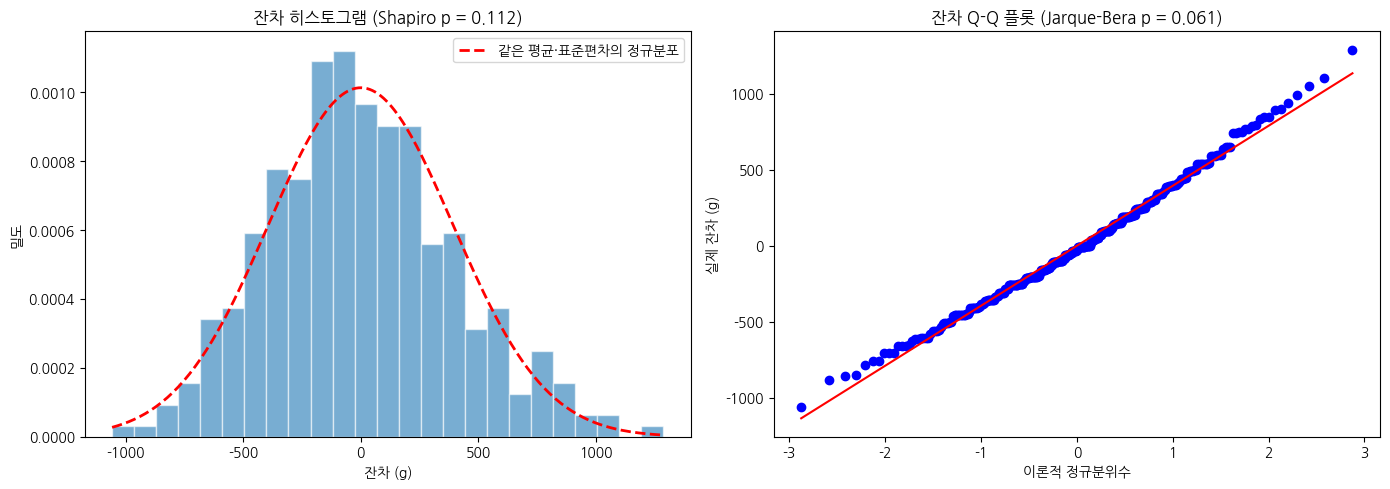

In [32]:
# 문제 5 · Q5 · 잔차의 정규성 검정
import os, platform, urllib.request
import numpy as np, seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.formula.api as smf
from scipy import stats

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

penguins = sns.load_dataset('penguins')
penguins_cleaned = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])
model = smf.ols('body_mass_g ~ flipper_length_mm', data=penguins_cleaned).fit()
residuals = model.resid
alpha = 0.05

# Shapiro-Wilk (잔차)
W, p_sw = stats.shapiro(residuals)
# Jarque-Bera (summary 표의 Prob(JB)와 같은 값)
jb, p_jb = stats.jarque_bera(residuals)

print("Q5 · 잔차의 정규성 검정")
print("H₀: 잔차가 정규분포를 따른다\n")
print(f"Shapiro-Wilk : W  = {W:.4f},  p = {p_sw:.4f}")
print(f"Jarque-Bera  : JB = {jb:.4f},  p = {p_jb:.4f}")
print(f"왜도 = {stats.skew(residuals):.3f},  첨도(초과) = {stats.kurtosis(residuals):.3f}\n")
for name, pv in [('Shapiro-Wilk', p_sw), ('Jarque-Bera', p_jb)]:
    if pv < alpha:
        print(f"{name}: p({pv:.4f}) < {alpha} -> H₀ 기각, 잔차가 정규분포가 아니라고 의심된다.")
    else:
        print(f"{name}: p({pv:.4f}) ≥ {alpha} -> H₀ 기각 못 함, 정규성 가정에 문제 없다.")
print("\n-> 문제 2에서는 '원래 변수'의 정규성이 기각됐지만,")
print("   회귀에서 필요한 건 '잔차'의 정규성이다. 잔차는 정규분포에 훨씬 가깝다.")
print(f"-> 표본이 n = {len(residuals)}으로 커서, 약간 벗어나도 t검정·p값은 신뢰할 만하다.")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].hist(residuals, bins=25, density=True, color='#1f77b4', alpha=0.6, edgecolor='white')
t = np.linspace(residuals.min(), residuals.max(), 200)
ax[0].plot(t, stats.norm.pdf(t, residuals.mean(), residuals.std()), 'r--', lw=2,
           label='같은 평균·표준편차의 정규분포')
ax[0].set_title(f'잔차 히스토그램 (Shapiro p = {p_sw:.3f})')
ax[0].set_xlabel('잔차 (g)'); ax[0].set_ylabel('밀도'); ax[0].legend()
stats.probplot(residuals, dist='norm', plot=ax[1])
ax[1].set_title(f'잔차 Q-Q 플롯 (Jarque-Bera p = {p_jb:.3f})')
ax[1].set_xlabel('이론적 정규분위수'); ax[1].set_ylabel('실제 잔차 (g)')
plt.tight_layout(); plt.show()

### Q6 · 보고 문장으로 정리해 봅시다

- 지금까지의 결과를 종합해, 우리 회귀모형을 보고서에 어떻게 적을지 **한 문장**으로 쓰세요.

- **기울기 + 유의성 + 설명력 + 진단 결과**를 모두 담아 보세요.

[보고에 쓰일 값]
  기울기   b = 49.69 g/mm (95% CI 46.70 ~ 52.67)
  유의성   t = 32.72, p < .001
  설명력   R² = 0.759
  등분산성 Breusch-Pagan p = 0.142 -> 충족
  정규성   Shapiro-Wilk p = 0.112 -> 충족
  잔차 패턴 종별 잔차 평균: Adelie +44g, Chinstrap -216g, Gentoo +66g

[보고 문장]
펭귄 342마리를 대상으로 날개 길이가 몸무게를 설명하는지 단순회귀분석한 결과, 날개 길이가 1mm 길어질 때 몸무게는 평균 49.69g(95% CI 46.70~52.67) 증가했으며 이는 통계적으로 유의했고(t = 32.72, p < .001), 모형은 몸무게 변동의 75.9%를 설명했으며(R² = 0.759), 잔차 진단에서 등분산성(Breusch-Pagan p = 0.142)과 정규성(Shapiro-Wilk p = 0.112) 가정은 충족되었으나 잔차가 종에 따라 체계적으로 달라 종을 함께 고려한 모형의 추가 검토가 필요하다.


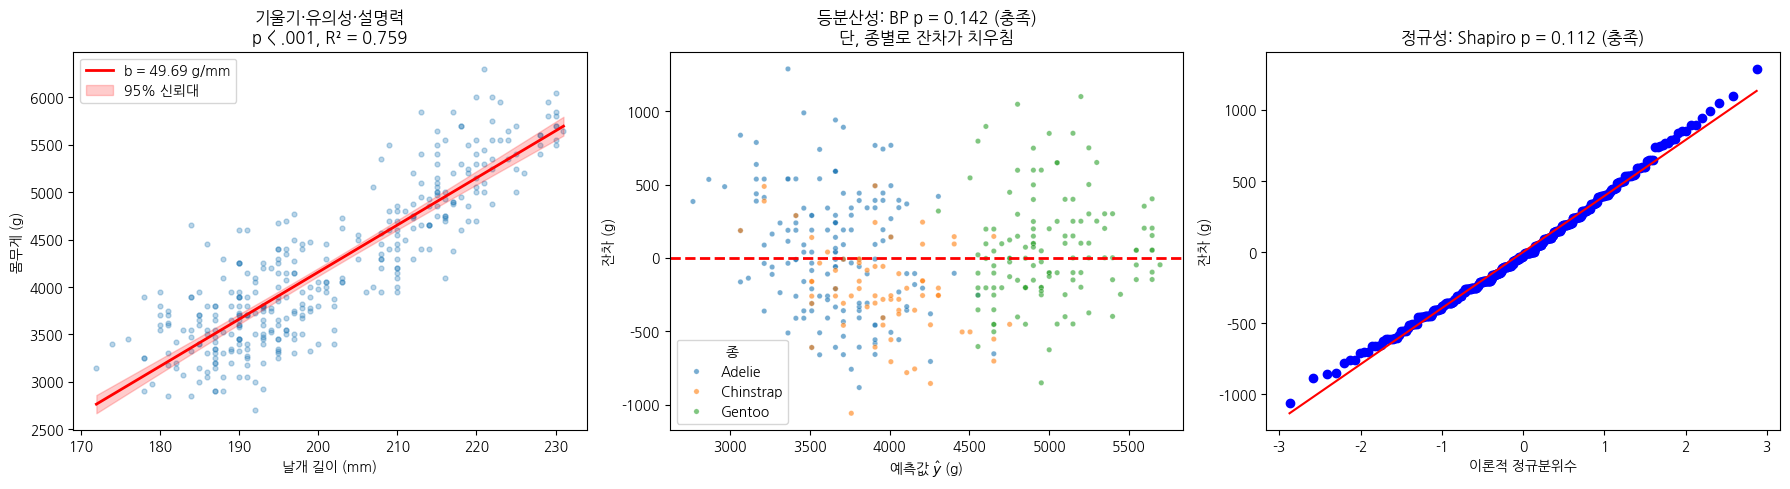

In [33]:
import os, platform, urllib.request
import numpy as np, seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy import stats

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

penguins = sns.load_dataset('penguins')
penguins_cleaned = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])
model = smf.ols('body_mass_g ~ flipper_length_mm', data=penguins_cleaned).fit()
X = 'flipper_length_mm'

# 보고에 필요한 값 모으기
n = int(model.nobs)
b = model.params[X]
lo, hi = model.conf_int().loc[X]
t, p_b = model.tvalues[X], model.pvalues[X]
r2 = model.rsquared
resid, fitted = model.resid, model.fittedvalues
_, p_bp, _, _ = het_breuschpagan(resid, model.model.exog)
_, p_sw = stats.shapiro(resid)
sp_mean = resid.groupby(penguins_cleaned['species']).mean()

p_txt = "p < .001" if p_b < 0.001 else f"p = {p_b:.3f}"
print("[보고에 쓰일 값]")
print(f"  기울기   b = {b:.2f} g/mm (95% CI {lo:.2f} ~ {hi:.2f})")
print(f"  유의성   t = {t:.2f}, {p_txt}")
print(f"  설명력   R² = {r2:.3f}")
print(f"  등분산성 Breusch-Pagan p = {p_bp:.3f} -> {'충족' if p_bp >= 0.05 else '위반'}")
print(f"  정규성   Shapiro-Wilk p = {p_sw:.3f} -> {'충족' if p_sw >= 0.05 else '위반'}")
print(f"  잔차 패턴 종별 잔차 평균: " + ", ".join(f"{k} {v:+.0f}g" for k, v in sp_mean.items()))

report = (f"펭귄 {n}마리를 대상으로 날개 길이가 몸무게를 설명하는지 단순회귀분석한 결과, "
          f"날개 길이가 1mm 길어질 때 몸무게는 평균 {b:.2f}g(95% CI {lo:.2f}~{hi:.2f}) 증가했으며 "
          f"이는 통계적으로 유의했고(t = {t:.2f}, {p_txt}), 모형은 몸무게 변동의 {r2*100:.1f}%를 "
          f"설명했으며(R² = {r2:.3f}), 잔차 진단에서 등분산성(Breusch-Pagan p = {p_bp:.3f})과 "
          f"정규성(Shapiro-Wilk p = {p_sw:.3f}) 가정은 충족되었으나 잔차가 종에 따라 "
          f"체계적으로 달라 종을 함께 고려한 모형의 추가 검토가 필요하다.")
print("\n[보고 문장]")
print(report)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
x, y = penguins_cleaned[X], penguins_cleaned['body_mass_g']
xs = np.linspace(x.min(), x.max(), 100)
pred = model.get_prediction(dict(flipper_length_mm=xs)).summary_frame()
ax[0].scatter(x, y, alpha=0.3, s=12)
ax[0].plot(xs, pred['mean'], 'r-', lw=2, label=f'b = {b:.2f} g/mm')
ax[0].fill_between(xs, pred['mean_ci_lower'], pred['mean_ci_upper'], color='red', alpha=0.2,
                   label='95% 신뢰대')
ax[0].set_title(f'기울기·유의성·설명력\n{p_txt}, R² = {r2:.3f}')
ax[0].set_xlabel('날개 길이 (mm)'); ax[0].set_ylabel('몸무게 (g)'); ax[0].legend(loc='upper left')
sns.scatterplot(x=fitted, y=resid, hue=penguins_cleaned['species'], s=15, alpha=0.6, ax=ax[1])
ax[1].axhline(0, color='red', ls='--', lw=2)
ax[1].set_title(f'등분산성: BP p = {p_bp:.3f} (충족)\n단, 종별로 잔차가 치우침')
ax[1].set_xlabel(r'예측값 $\hat{y}$ (g)'); ax[1].set_ylabel('잔차 (g)'); ax[1].legend(title='종')
stats.probplot(resid, dist='norm', plot=ax[2])
ax[2].set_title(f'정규성: Shapiro p = {p_sw:.3f} (충족)')
ax[2].set_xlabel('이론적 정규분위수'); ax[2].set_ylabel('잔차 (g)')
plt.tight_layout(); plt.show()

### 💬 정리 · 결과를 말로 설명해 보기

- Q3·Q4에서 우리 모형의 잔차는 어떤 상태였나요? 이 결과를 근거로 문제 3·4의 해석을 신뢰할 수 있을까요?

- Q5의 두 잔차 산점도는 어떻게 달랐나요? 비교군에서 관찰된 모양을 강의에서 배운 용어로 무엇이라 부르나요?

- 비교군처럼 등분산성이 깨졌을 때, **잘못된 것은 기울기 값 자체인가요, 아니면 그 값의 통계적 해석인가요?**

- R²가 1이 아니라는 것은 설명되지 않은 변동이 남아 있다는 뜻입니다. `penguins` 안에서 몸무게에 영향을 줄 만한데 우리 모델이 놓치고 있는 변수는 무엇일까요?

- 그 변수들을 모델에 함께 넣으려면 어떤 분석이 필요할까요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 강의 7장은 이렇게 적었습니다 — _"파라미터 값이 잘못되었다는 뜻이 아니라, 이 값의 통계적 해석(유의성·신뢰구간)과 예측 결과를 신뢰할 수 없다는 의미"_. 세 번째 질문의 답이 여기 있습니다.

- 비교군의 잔차가 퍼지는 모양을 강의의 3케이스 그림(정규성 O·등분산 O / X·O / O·X)과 맞춰 보세요.

- 놓친 변수 후보는 문제 1의 그림에 이미 있습니다. 그 변수를 모델에 함께 넣는 분석의 이름은 다음 8장의 제목입니다.

</details>

1. Q3·Q4에서 우리 모형의 잔차 상태
   잔차 평균 ≈ 0, 퍼짐이 예측값과 무관하게 일정(BP p = 0.142 -> 등분산).
   다만 종별로 치우침: Adelie +44g, Chinstrap -216g, Gentoo +66g
   -> 표준오차·t·p값의 전제가 지켜졌으므로 문제 3·4의 유의성 해석은 신뢰할 수 있다.
   -> 단, 종이 빠진 영향으로 기울기 값 자체는 약간 치우쳤을 수 있다.

2. Q5의 두 잔차 산점도 차이
   날개 모형: 0 주위에 고르게 퍼짐 (BP p = 0.142)
   부리 모형: 예측값이 커질수록 위아래로 크게 벌어지는 깔때기 모양 (BP p = 9.9e-19)
   -> 이 모양을 '이분산성(heteroscedasticity)'이라고 부른다.

3. 등분산성이 깨지면 무엇이 잘못되나? -> 기울기 값이 아니라 '통계적 해석'
   일반 OLS     : 기울기 = 87.42,  표준오차 = 6.40,  p = 3.81e-34
   강건(HC3) SE : 기울기 = 87.42,  표준오차 = 6.90,  p = 2.09e-30
   -> 기울기는 그대로, 표준오차(그리고 t·p·신뢰구간)만 달라진다.
   -> 이분산성은 '불확실성 계산'을 틀리게 만든다. (단, 부리 모형은 종 누락으로
      기울기 자체도 치우쳤을 수 있다 -> 이건 이분산성이 아니라 누락변수 문제)

4. 모델이 놓친, 몸무게에 영향을 줄 만한 변수
   species(종), sex(성별), island(서식지), bill_length_mm·bill_depth_mm(부리 크기)
   -> 특히 종과 성별: 종별 몸집 차이, 수컷이 대체로 더 무거움

5. 여러 변수를 함께 넣으려면 -> 다중회귀분석 (범주형은 더미변수로)
   (성별 결측 제외, n = 333로 세 모형을 같은 데이터에서 비교)
   예: smf.ols('body_mass_g ~ flipper_length_mm + C(species) + C(sex)', data=..

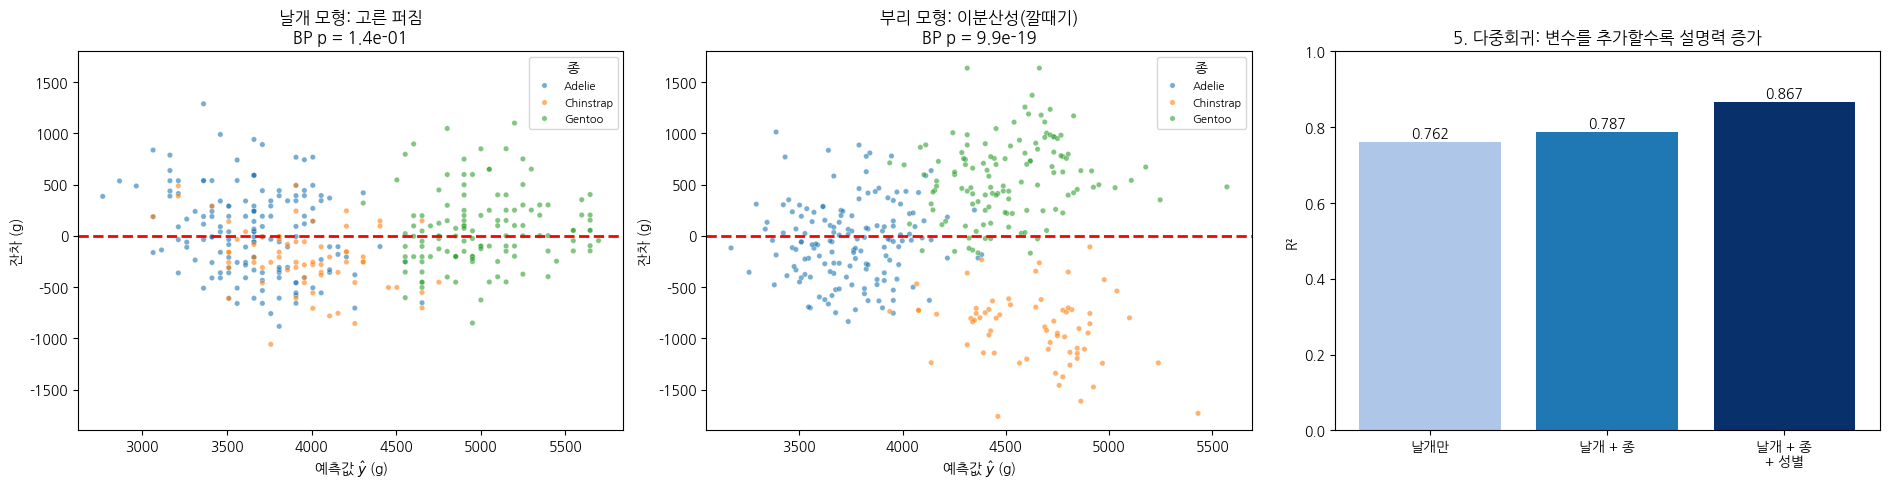

In [34]:
import os, platform, urllib.request
import numpy as np, seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan

s = platform.system()
if s == 'Windows': plt.rc('font', family='Malgun Gothic')
elif s == 'Darwin': plt.rc('font', family='AppleGothic')
else:
    p = '/tmp/NG.ttf'
    if not os.path.exists(p):
        urllib.request.urlretrieve('https://github.com/google/fonts'
            '/raw/main/ofl/nanumgothic/NanumGothic-Regular.ttf', p)
    fm.fontManager.addfont(p)
    plt.rc('font', family=fm.FontProperties(fname=p).get_name())
plt.rc('axes', unicode_minus=False)

penguins = sns.load_dataset('penguins')
pc = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm', 'bill_length_mm'])
model = smf.ols('body_mass_g ~ flipper_length_mm', data=pc).fit()
model_bill = smf.ols('body_mass_g ~ bill_length_mm', data=pc).fit()
bp = lambda m: het_breuschpagan(m.resid, m.model.exog)[1]
sp_mean = model.resid.groupby(pc['species']).mean()

print("1. Q3·Q4에서 우리 모형의 잔차 상태")
print(f"   잔차 평균 ≈ 0, 퍼짐이 예측값과 무관하게 일정(BP p = {bp(model):.3f} -> 등분산).")
print("   다만 종별로 치우침: " + ", ".join(f"{k} {v:+.0f}g" for k, v in sp_mean.items()))
print("   -> 표준오차·t·p값의 전제가 지켜졌으므로 문제 3·4의 유의성 해석은 신뢰할 수 있다.")
print("   -> 단, 종이 빠진 영향으로 기울기 값 자체는 약간 치우쳤을 수 있다.\n")

print("2. Q5의 두 잔차 산점도 차이")
print(f"   날개 모형: 0 주위에 고르게 퍼짐 (BP p = {bp(model):.3f})")
print(f"   부리 모형: 예측값이 커질수록 위아래로 크게 벌어지는 깔때기 모양 (BP p = {bp(model_bill):.1e})")
print("   -> 이 모양을 '이분산성(heteroscedasticity)'이라고 부른다.\n")

rob = model_bill.get_robustcov_results(cov_type='HC3')
b_c, se_c, p_c = model_bill.params['bill_length_mm'], model_bill.bse['bill_length_mm'], model_bill.pvalues['bill_length_mm']
b_r, se_r, p_r = rob.params[1], rob.bse[1], rob.pvalues[1]
print("3. 등분산성이 깨지면 무엇이 잘못되나? -> 기울기 값이 아니라 '통계적 해석'")
print(f"   일반 OLS     : 기울기 = {b_c:.2f},  표준오차 = {se_c:.2f},  p = {p_c:.2e}")
print(f"   강건(HC3) SE : 기울기 = {b_r:.2f},  표준오차 = {se_r:.2f},  p = {p_r:.2e}")
print("   -> 기울기는 그대로, 표준오차(그리고 t·p·신뢰구간)만 달라진다.")
print("   -> 이분산성은 '불확실성 계산'을 틀리게 만든다. (단, 부리 모형은 종 누락으로")
print("      기울기 자체도 치우쳤을 수 있다 -> 이건 이분산성이 아니라 누락변수 문제)\n")

print("4. 모델이 놓친, 몸무게에 영향을 줄 만한 변수")
print("   species(종), sex(성별), island(서식지), bill_length_mm·bill_depth_mm(부리 크기)")
print("   -> 특히 종과 성별: 종별 몸집 차이, 수컷이 대체로 더 무거움\n")

full = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm', 'species', 'sex'])
m1 = smf.ols('body_mass_g ~ flipper_length_mm', data=full).fit()
m2 = smf.ols('body_mass_g ~ flipper_length_mm + C(species)', data=full).fit()
m3 = smf.ols('body_mass_g ~ flipper_length_mm + C(species) + C(sex)', data=full).fit()
print("5. 여러 변수를 함께 넣으려면 -> 다중회귀분석 (범주형은 더미변수로)")
print(f"   (성별 결측 제외, n = {len(full)}로 세 모형을 같은 데이터에서 비교)")
print("   예: smf.ols('body_mass_g ~ flipper_length_mm + C(species) + C(sex)', data=...)")
for name, m in [('날개만', m1), ('날개 + 종', m2), ('날개 + 종 + 성별', m3)]:
    print(f"   {name:<14} R² = {m.rsquared:.3f},  수정 R² = {m.rsquared_adj:.3f},  BP p = {bp(m):.3f}")
print("   -> 변수를 추가하자 설명력이 크게 오르고, 종별 잔차 평균은 0으로 맞춰진다.")
print("   -> 단, 변수를 넣었다고 진단이 자동 통과는 아니다(날개+종 모형 BP p < 0.05).")
print("      다중회귀도 잔차 진단을 다시 해야 한다.")

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
for a_, m, t in [(ax[0], model, '날개 모형: 고른 퍼짐'), (ax[1], model_bill, '부리 모형: 이분산성(깔때기)')]:
    sns.scatterplot(x=m.fittedvalues, y=m.resid, hue=pc['species'], s=15, alpha=0.6, ax=a_)
    a_.axhline(0, color='red', ls='--', lw=2)
    a_.set_title(f'{t}\nBP p = {bp(m):.1e}')
    a_.set_xlabel(r'예측값 $\hat{y}$ (g)'); a_.set_ylabel('잔차 (g)'); a_.legend(title='종', fontsize=8)
ax[0].set_ylim(-1900, 1800); ax[1].set_ylim(-1900, 1800)
names = ['날개만', '날개 + 종', '날개 + 종\n+ 성별']
r2s = [m1.rsquared, m2.rsquared, m3.rsquared]
ax[2].bar(names, r2s, color=['#aec7e8', '#1f77b4', '#08306b'])
for i, v in enumerate(r2s): ax[2].text(i, v + 0.01, f'{v:.3f}', ha='center')
ax[2].set_ylim(0, 1); ax[2].set_ylabel('R²')
ax[2].set_title('5. 다중회귀: 변수를 추가할수록 설명력 증가')
plt.tight_layout(); plt.show()